# 302_05 — PSBPM-FD con cuatro predictores y tres intervalos contra FAR y RF · Escenario multimodal · **barrido en $M$**

Copia del `200_05` sobre los artefactos de la 302 y lo que persiste `302_04`: una fila por predictor en el Bloque A, una banda por construcción en el Bloque B (`111_*` contra el FAR), §9 y §10 sobre la ventana de detalle. Cálculo en `fit/comparacion_barrido.py`, figuras en `graphics/viz_comparacion.py`.

## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd
import json

import numpy as np

from model_psbp_fd.fit.convergencia_barrido import cargar_artefactos
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB, cargar_representaciones, serie_origenes,
)
from model_psbp_fd.fit.comparacion_barrido import (
    G_FAR, G_PSG, G_PSB, PISO,
    preparar_diseno, info_generador, ajustar_far, ajustar_rf, cargar_psbp,
    tablas_modelos, verificar_cadena_modelos,
    construir_bandas, tabla_bloque_B, ventana_bloque_B,
    ganadores_por_ventana, resumen_min_max, promedio_vs_M,
    origenes_extremos, contraste_origenes, nombre_psbp, validar_comportamientos_barrido,
    G_PSS, G_PSH, bloqueB_contra_far,
)
from model_psbp_fd.fit.evaluacion_barrido import INTERVALOS as INTERVALOS_TODOS
from model_psbp_fd.fit.resumenes_predictiva import PREDICTORES as PREDICTORES_TODOS
from model_psbp_fd.graphics import (
    plot_ventana_movil, ESTILOS_MODELOS, ESTILOS_MODELOS_PREDICTORES, plot_validacion_observado,
    plot_ganador_modelo, plot_metricas_vs_M, plot_bandas_contraste,
)
from model_psbp_fd.fit.comportamientos import cargar_comportamientos, validar_observado
from model_psbp_fd.fit.intervalos_predictiva import ancho_tramos, cobertura_tramos
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Mismos valores que 302_01 §1.1 (la 202 con otro BASENAME).
VARIANTE     = "chungEscX"
BASENAME     = f"escenario_302_{VARIANTE}"
ESCENARIO_ID = 1      # escenario multimodal (único)
REPLICA_ID   = 1      # réplica Monte Carlo
M_FPCA_LIST  = (3, 4, 5, 6)

# Propias de la comparación. Ventanas, nivel y objetivo se LEEN de eval_config.json
# (artefacto copiado de 202_01): no se redeclaran aquí.
PESOS_TAU = None          # cuadratura trapezoidal por defecto
PREFIJO   = 70            # este notebook escribe 70-83 en cada M y 96-99, 105-107, 111 en el barrido
INTERVALOS  = INTERVALOS_TODOS    # equicolas, simultanea, hdr: una banda del PSBPM-FD por construcción
N_DETALLE   = 10        # orígenes consecutivos de prueba para el análisis predictivo (§9, §10)
T0_DETALLE  = None      # el _05 LEE la ventana del _04 (112_ventana_detalle.json); un entero sólo la verifica
PREDICTORES = PREDICTORES_TODOS   # una fila del PSBPM-FD por predictor puntual (302_04 §3)

# FAR (§3.1): tope del barrido de kn (acota en K, no en L) y criterio de far.cv.
KN_MAX      = 12
CRITERIO_KN = "L2"

# Random Forest (§3.2): hiperparámetros fijos entre escenarios y entre puntos del barrido.
SEED_ML   = 20260830
PARAMS_RF = dict(n_estimators=500, min_samples_leaf=5, max_features="sqrt",
                 random_state=SEED_ML, n_jobs=-1)

# Bloque B (§5): FAR con banda gaussiana de residuos de train y PSBPM-FD con su banda
# nativa (cuantiles de su predictiva).
IC_POR_TAU                = True    # sigma_eps(tau) punto a punto (False = ancho constante)
IC_CORRECCION_ESTIMACION  = True    # infla sigma por sqrt(1 + kn/n_train)
IC_PSBP_TAMBIEN_GAUSSIANA = False   # control opcional: no se corre (sólo FAR gaussiano y PSBPM-FD nativo)

# §9: por qué métrica se eligen los orígenes extremos, cuántos, qué dos bandas se
# contrastan (prefijos, en orden) y en qué M (None = todos).
METRICA_SEL_IC     = "rmse_f"     # una de METRICAS_A_COLS
N_EXTREMOS         = 5
BANDA_A_CONTRASTAR = ("FAR", "PSBPM-FD (predictiva")
M_DETALLE          = None

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]
assert METRICA_SEL_IC in METRICAS_A_COLS[:3], "METRICA_SEL_IC: mae_f, rmse_f o linf_medio."

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASENAME, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASENAME, ESCENARIO_ID, REPLICA_ID, project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}   (archivos 96-99, 105-107)")

# Ancho de referencia del documento: None = el de siempre (el del medio, 30; decisión 2026-10-12, para no
# reejecutar el _04). Un entero de VENTANAS_W sobrescribe DIS["W_REF"] sin tocar eval_config.json.
W_REF_DOC = None


EXPERIMENT_BASE : escenario_302_chungEscX_1_r01
barrido en M    : [3, 4, 5, 6]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_barrido_M   (archivos 96-99, 105-107)


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASENAME, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True)
DIS  = cargar_representaciones(EST)
ORIG = serie_origenes(DIS)

T0, N_LAGS, NIVEL = DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W = DIS["VENTANAS_W"]
if W_REF_DOC is not None:
    assert int(W_REF_DOC) in VENTANAS_W, f"W_REF_DOC={W_REF_DOC} no está en {VENTANAS_W}"
    DIS["W_REF"] = int(W_REF_DOC)
W_REF = DIS["W_REF"]
print(f"ancho de referencia de este notebook: w = {W_REF}" + ("  (W_REF_DOC)" if W_REF_DOC is not None else ""))
grilla, X_obj_ev  = DIS["grilla"], ORIG["X_obj_ev"]
t_orig, es_train  = ORIG["t_orig"], ORIG["es_train"]

  M  comp  cadenas  covariables  seed_base
  3     3        3            6  41232
  4     4        3            8  41232
  5     5        3           10  41232
  6     6        3           12  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 3)
M=3  FPCA M=3 K=10  var. explicada=85.2356%  ·  curvas (1000, 75)
M=4  FPCA M=4 K=10  var. explicada=91.5213%  ·  curvas (1000, 75)


M=5  FPCA M=5 K=10  var. explicada=95.5660%  ·  curvas (1000, 75)
M=6  FPCA M=6 K=10  var. explicada=97.6776%  ·  curvas (1000, 75)

OK 4 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=1000 T0=700 n_lags=2   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95


In [4]:
# Ventana de detalle: la que eligió el _04 (§3.2), leída de 112_ventana_detalle.json; no se recalcula.
VD = json.loads((PATH_BARRIDO / "112_ventana_detalle.json").read_text(encoding="utf-8"))
assert VD["n"] == N_DETALLE, f"el _04 usó N_DETALLE={VD['n']}"
assert T0_DETALLE is None or int(T0_DETALLE) == VD["t0"], f"el _04 usó T0_DETALLE={VD['t0']}"
T0_DET   = int(VD["t0"])
IDX_DET  = np.flatnonzero((t_orig >= T0_DET) & (t_orig < T0_DET + N_DETALLE))
assert len(IDX_DET) == N_DETALLE and not es_train[IDX_DET].any()
MASK_DET = np.isin(np.arange(len(t_orig)), IDX_DET)
T_DET    = t_orig[IDX_DET]
print(f"Ventana de detalle del _04: t = {T0_DET}..{T0_DET + N_DETALLE - 1}   ·   {VD['criterio']}: {VD['valor']}")

Ventana de detalle del _04: t = 776..785   ·   orígenes con K >= 2 en la predictiva oráculo (algún M de [3, 4, 5, 6]), suma sobre la ventana: 3.0


## 2. Validaciones para aplicar los modelos

In [5]:
preparar_diseno(EST, DIS, ORIG)
info_generador(EST[next(iter(EST))], N_LAGS)

origenes evaluados: 998  (train 698 · test 300)
MISE del TRUNCAMIENTO FPCA (piso comun a todos los modelos de cada M):
  M= 3   train 0.177325   test 0.174800
  M= 4   train 0.101867   test 0.098823
  M= 5   train 0.053371   test 0.049905
  M= 6   train 0.027984   test 0.026036
R^2 L2 del oraculo de Bayes (2 rezagos) = 0.4463   ·   mejor lineal en los mismos rezagos = 0.4232


## 3. Los competidores

### 3.1 FAR(p), p = N_LAGS, sobre los coeficientes de la base en la métrica $L^2$

Blanqueo con la Cholesky de la Gram (identidad con base ortonormal, verificado con `assert`); `pesos="conteo"`.

In [6]:
FAR = ajustar_far(EST, DIS, ORIG, KN_MAX, CRITERIO_KN)

base: K = 10   ·   cond(W) = 1.00   ·   ||x||_L2 == ||theta_w||_2 (error relativo 1.00e-10)
far.cv: hold-out de las ultimas 140 curvas de train · kn_max = 10
  kn         L1         L2       Linf      L1max      L2max    Linfmax
   1     0.1777     0.2547     0.5904     0.2999     0.3897     1.1818
   2     0.1755     0.2497     0.5738     0.3106     0.3902     1.1287
   3     0.1739     0.2472     0.5630     0.3084     0.3884     1.1254
   4     0.1742     0.2473     0.5610     0.3079     0.3886     1.1129
   5     0.1742     0.2469     0.5604     0.3098     0.3877     1.0853
   6     0.1740     0.2470     0.5606     0.3109     0.3888     1.0662
   7     0.1735     0.2466     0.5599     0.3069     0.3897     1.0916
   8     0.1732     0.2464     0.5605     0.3062     0.3895     1.0997  <-
   9     0.1729     0.2465     0.5613     0.3065     0.3898     1.1029
  10     0.1733     0.2471     0.5620     0.3055     0.3884     1.0910
kn elegido por L2: 8   (L1 -> 9, Linf -> 7)   amplitud re

### 3.2 Random Forest

Un bosque por componente con las mismas covariables que el PSBPM-FD (las covariables cruzadas); el orden $1..N_{lags}$ se elige por ventanas de train ganadas en `mae_f`.

In [7]:
ajustar_rf(EST, DIS, ORIG, PARAMS_RF, PESOS_TAU)

M=3: RF orden=2   (orden elegido por ventanas de train: 2 (99.1% de 669) de [1, 2])   ·   3 modelos univariantes (rezagos de todas las componentes)


M=4: RF orden=2   (orden elegido por ventanas de train: 2 (71.4% de 669) de [1, 2])   ·   4 modelos univariantes (rezagos de todas las componentes)


M=5: RF orden=2   (orden elegido por ventanas de train: 2 (97.3% de 669) de [1, 2])   ·   5 modelos univariantes (rezagos de todas las componentes)


M=6: RF orden=2   (orden elegido por ventanas de train: 2 (97.2% de 669) de [1, 2])   ·   6 modelos univariantes (rezagos de todas las componentes)


### 3.3 PSBPM-FD

Predictores e intervalos se leen de `banda_funcional_psbp.npz`; una fila `PSBPM-FD (<predictor>)` por predictor y las bandas con la esperanza.

In [8]:
M_OK = cargar_psbp(EST, DIS, ORIG, predictores=PREDICTORES, intervalos=INTERVALOS)

OK PSBPM-FD leido del _04 en M = [3, 4, 5, 6]


## 4. Bloque A: error puntual, todos los modelos

MAE, RMSE y error máximo sobre la misma ventana móvil, para FAR, RF y cada predictor del PSBPM-FD.

OK cadena L1 <= L2 <= Linf verificada en 4 puntos (w=30)


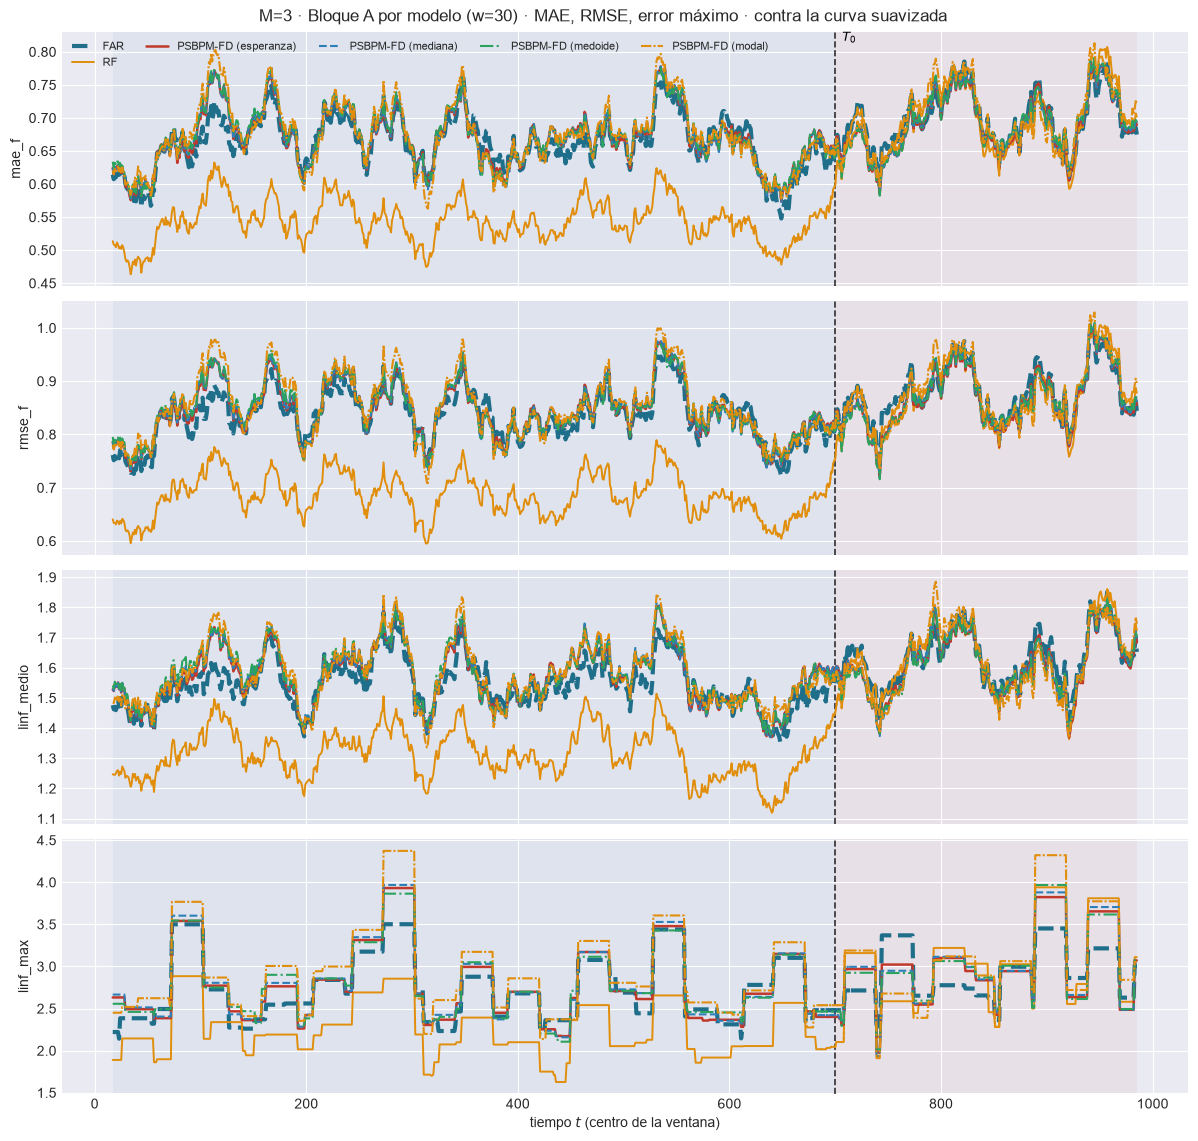

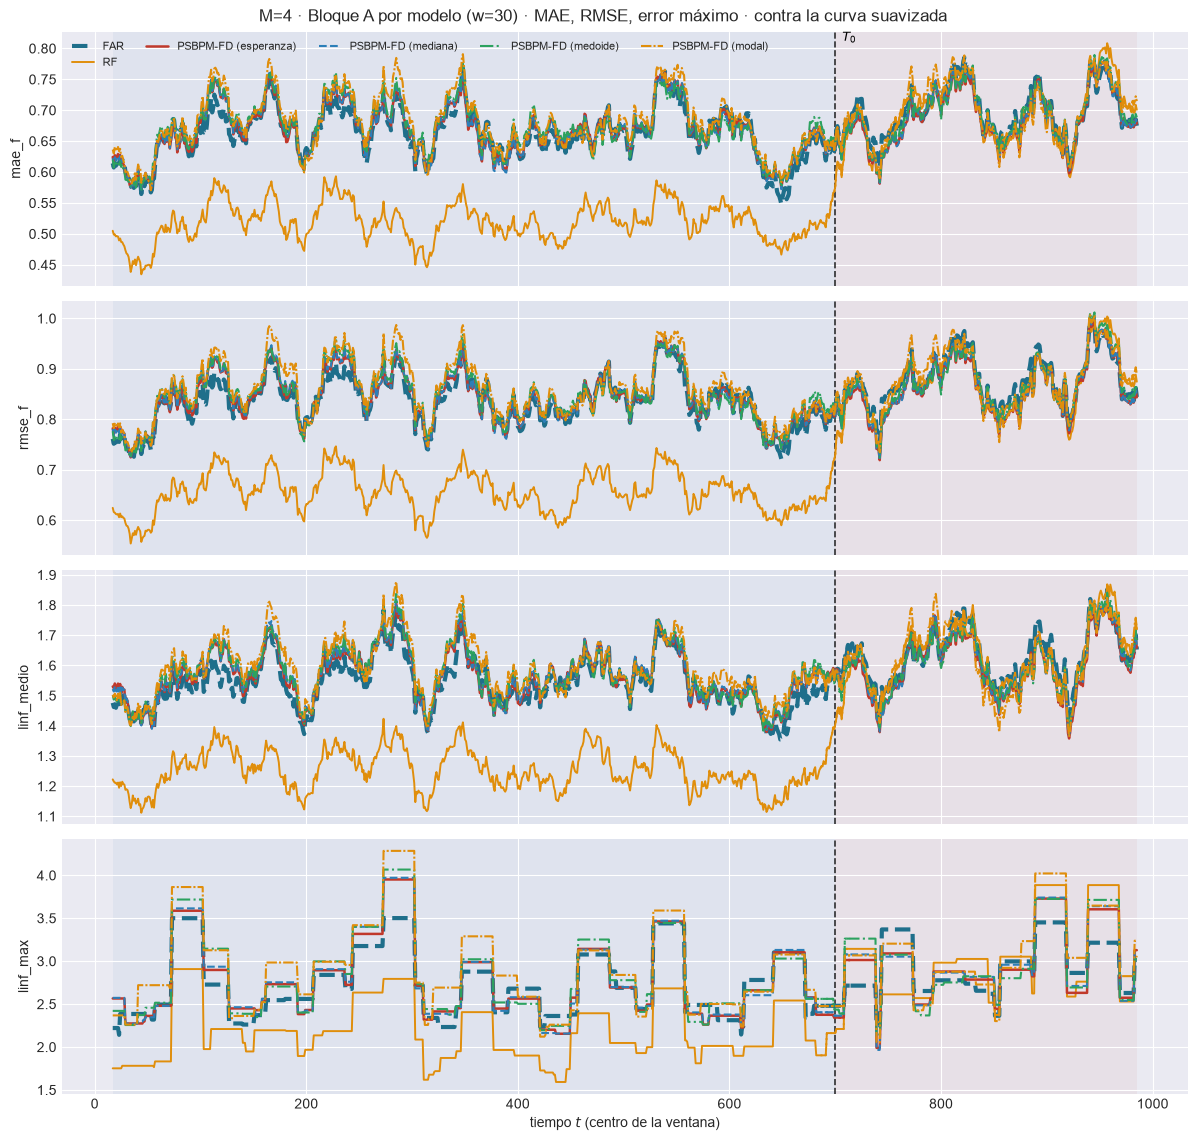

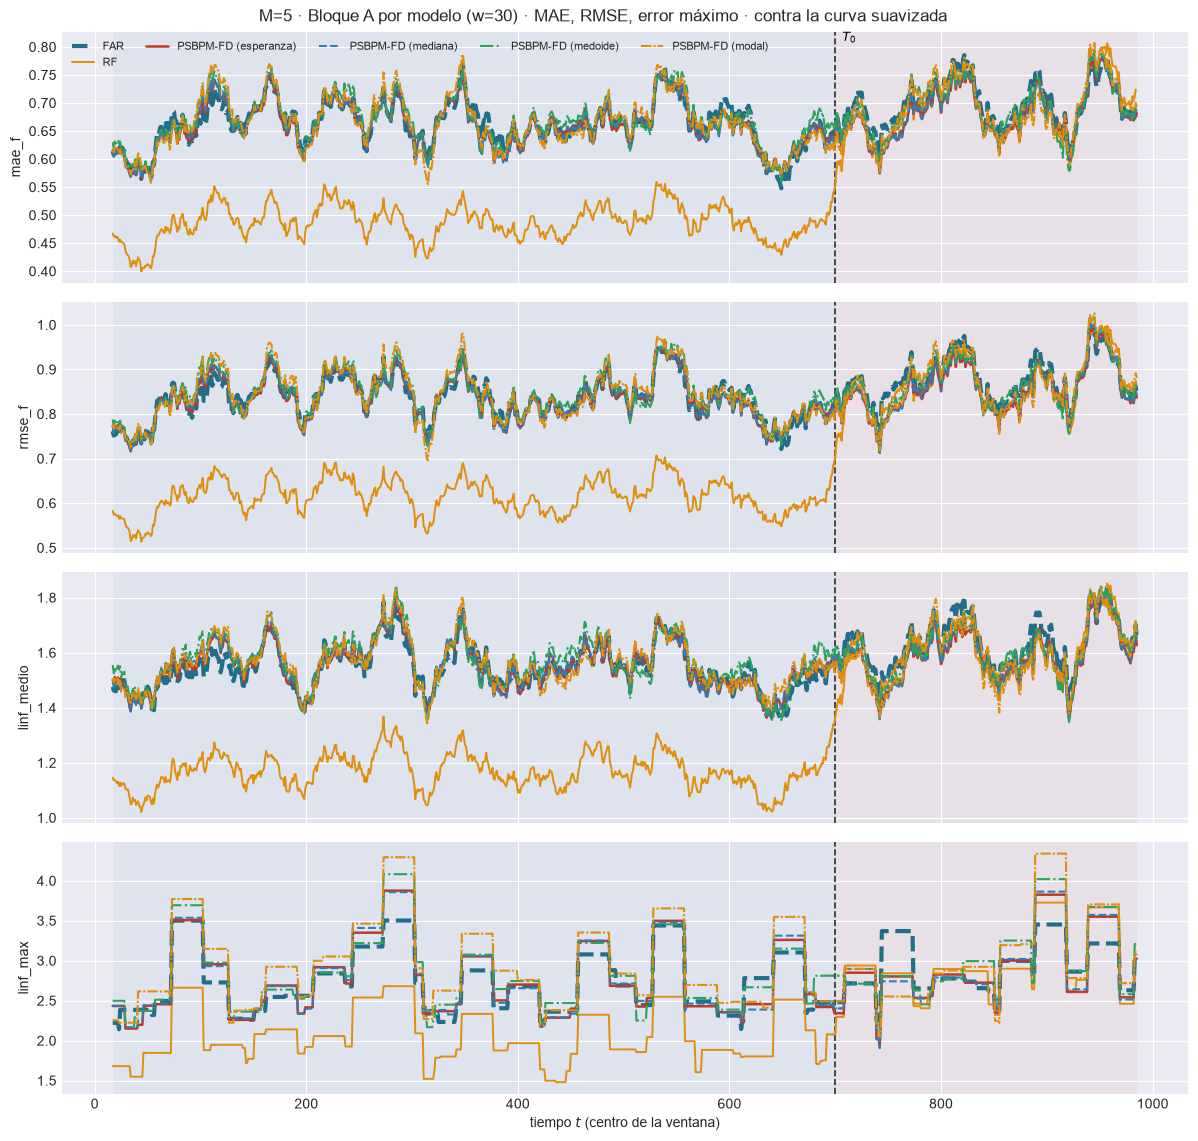

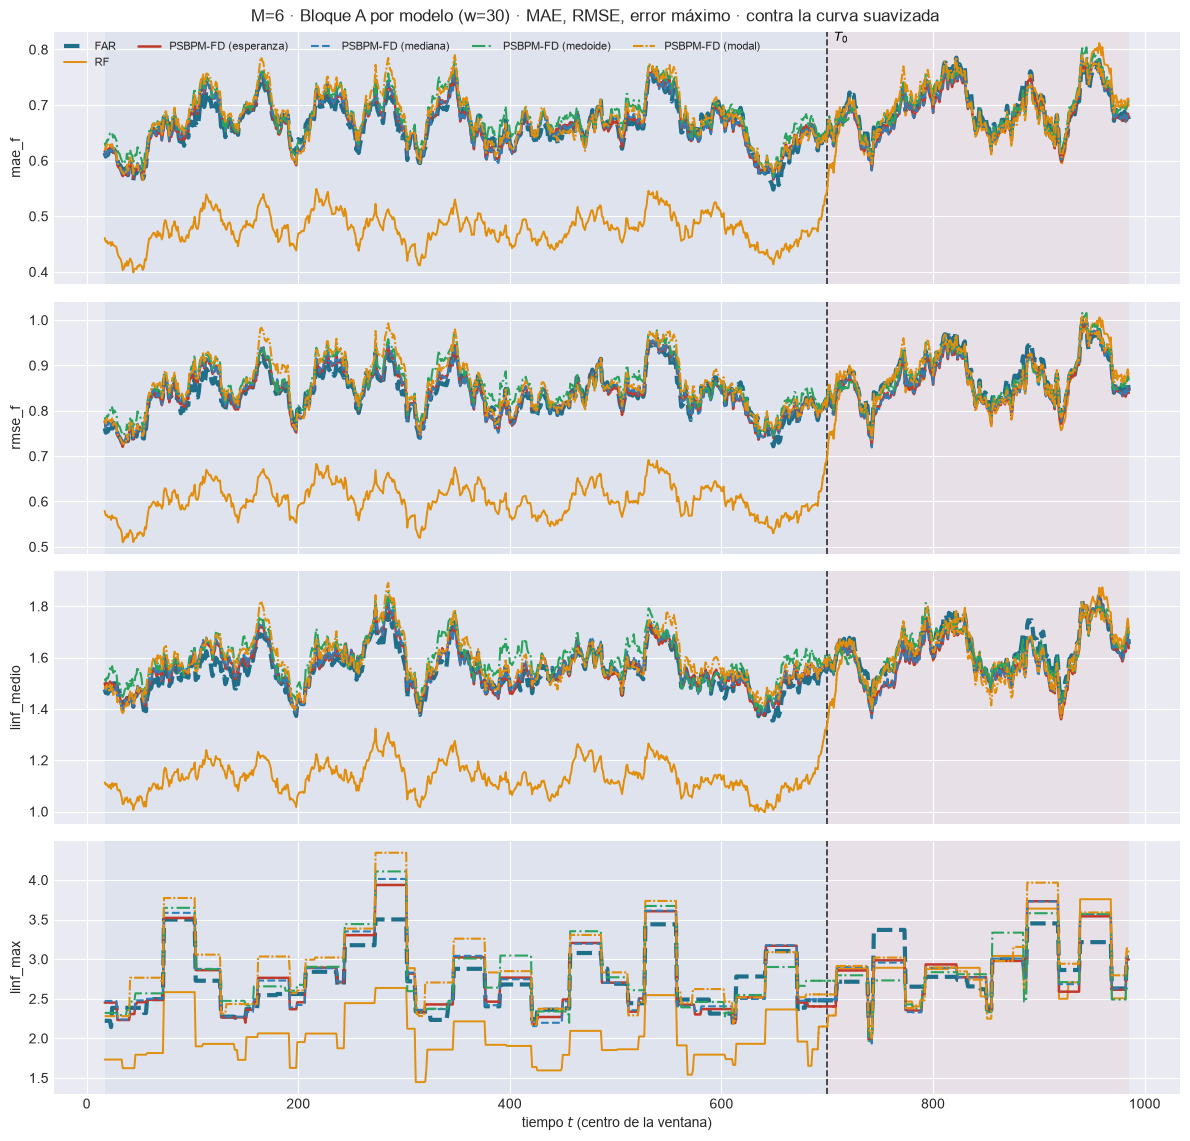

In [9]:
for M in M_OK:
    tablas_modelos(EST[M], DIS, ORIG, PESOS_TAU, PREFIJO)
verificar_cadena_modelos(EST, W_REF)

# Una figura por M; el piso de truncamiento va en las tablas pero no en la figura.
for M in M_OK:
    e = EST[M]
    tw = e["tablas_w"][W_REF]
    tf = tw[tw["modelo"] != PISO].copy()
    tf.attrs["w"] = W_REF
    plot_ventana_movil(
        tf, T0, METRICAS_A_COLS, columna_grupo="modelo", estilos=ESTILOS_MODELOS_PREDICTORES,
        title=f"M={M} · Bloque A por modelo (w={W_REF}) · MAE, RMSE, error máximo · contra la curva suavizada",
        save_path=str(e["paths"]["out_report"] / f"{PREFIJO + 8}_ventana_bloqueA_modelos_w{W_REF}.png"),
        verbose=False)
    plt.show()

## 5. Bloque B: intervalos, sólo FAR y PSBPM-FD (tres construcciones)

El RF no tiene mecanismo de intervalo propio. Del PSBPM-FD, equi-colas, simultánea y HDR con la esperanza, y el contraste misma predictiva, distinta construcción.

In [10]:
for M in M_OK:
    e = EST[M]
    construir_bandas(e, DIS, ORIG, IC_POR_TAU, IC_CORRECCION_ESTIMACION, IC_PSBP_TAMBIEN_GAUSSIANA,
                     intervalos_psbp=INTERVALOS)
    B_df = tabla_bloque_B(e, DIS, ORIG)
    display(B_df.loc["test"].style
            .format({"winkler": "{:.4f}", "picp": "{:.4f}", "ee_picp": "{:.4f}", "ace": "{:+.4f}",
                     "mpiw": "{:.4f}", "picp_simultaneo": "{:.4f}"})
            .background_gradient(subset=["winkler"], cmap="RdYlGn_r")
            .set_caption(f"M={M} · Bloque B, bloque de PRUEBA · PRIMARIA: winkler · nivel nominal {NIVEL:.0%}"))

M=3  kn=8  correccion=1.0057  sigma_eps(tau) del FAR: min=0.7438 max=0.9020 (razon 1.21)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.1337   región de máxima densidad - equi-colas = -0.0010
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.7047   región de máxima densidad - equi-colas = +0.0071


M=4  kn=8  correccion=1.0057  sigma_eps(tau) del FAR: min=0.7438 max=0.9020 (razon 1.21)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.5883   región de máxima densidad - equi-colas = +0.0045
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.8715   región de máxima densidad - equi-colas = +0.0032


M=5  kn=8  correccion=1.0057  sigma_eps(tau) del FAR: min=0.7438 max=0.9020 (razon 1.21)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.8330   región de máxima densidad - equi-colas = +0.0102
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.9454   región de máxima densidad - equi-colas = +0.0073


M=6  kn=8  correccion=1.0057  sigma_eps(tau) del FAR: min=0.7438 max=0.9020 (razon 1.21)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.9109   región de máxima densidad - equi-colas = +0.0034
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.9632   región de máxima densidad - equi-colas = +0.0021


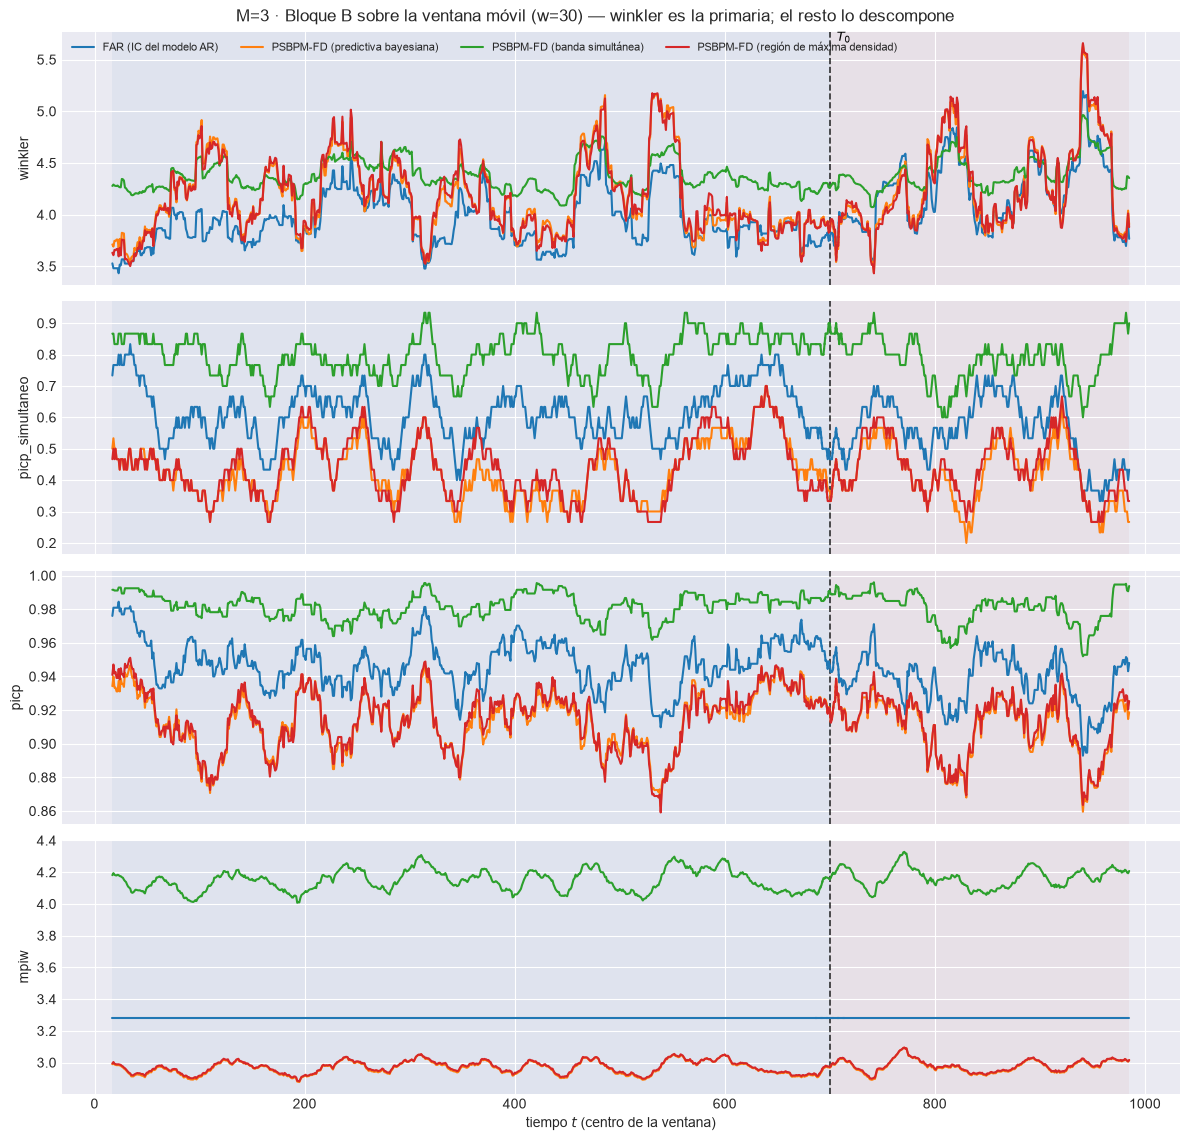

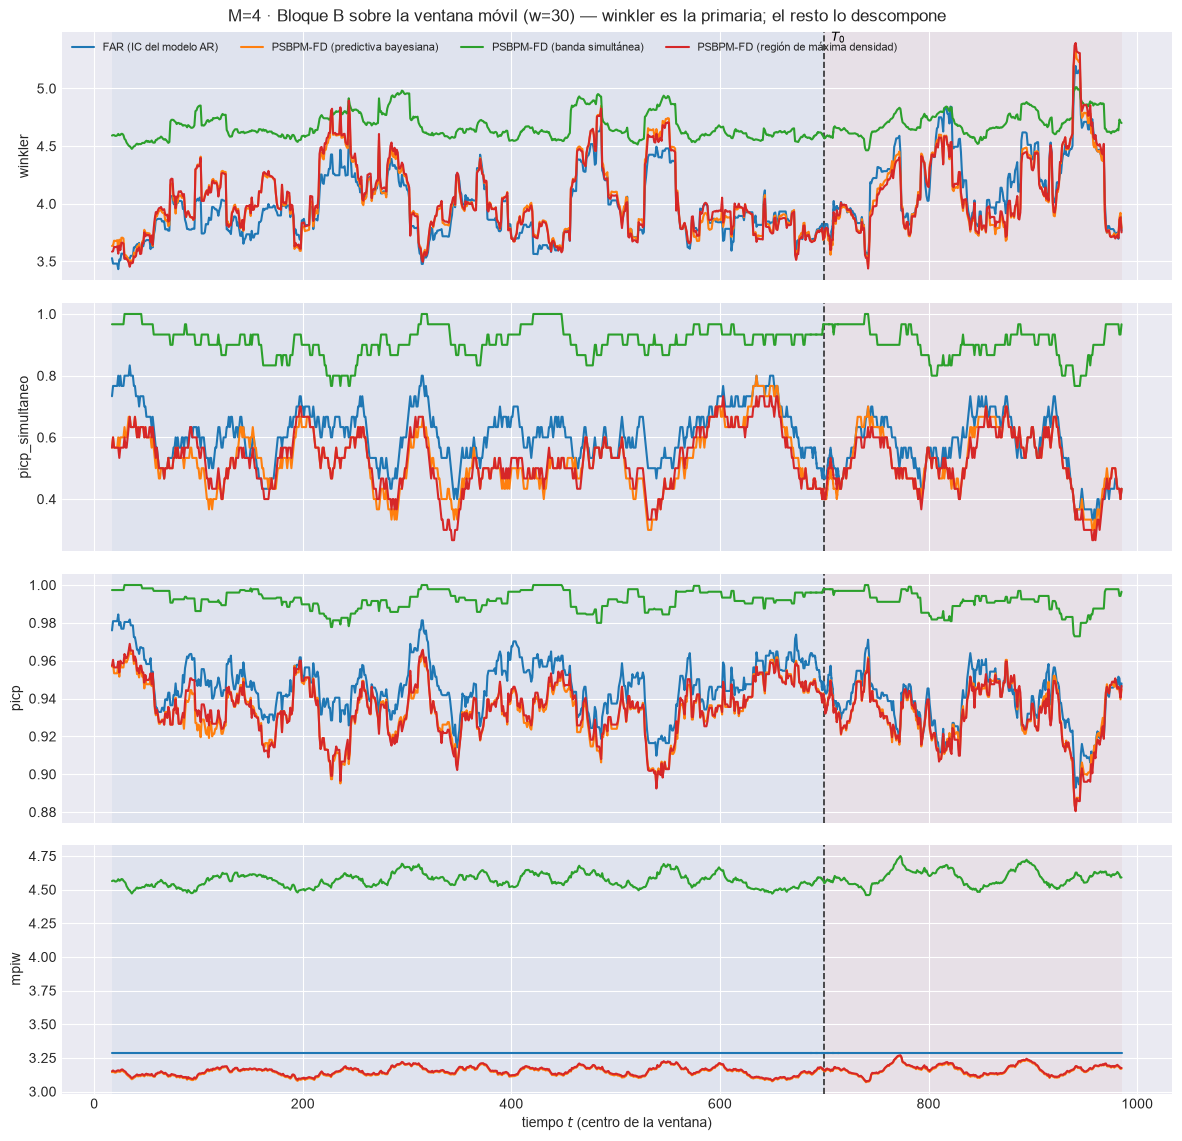

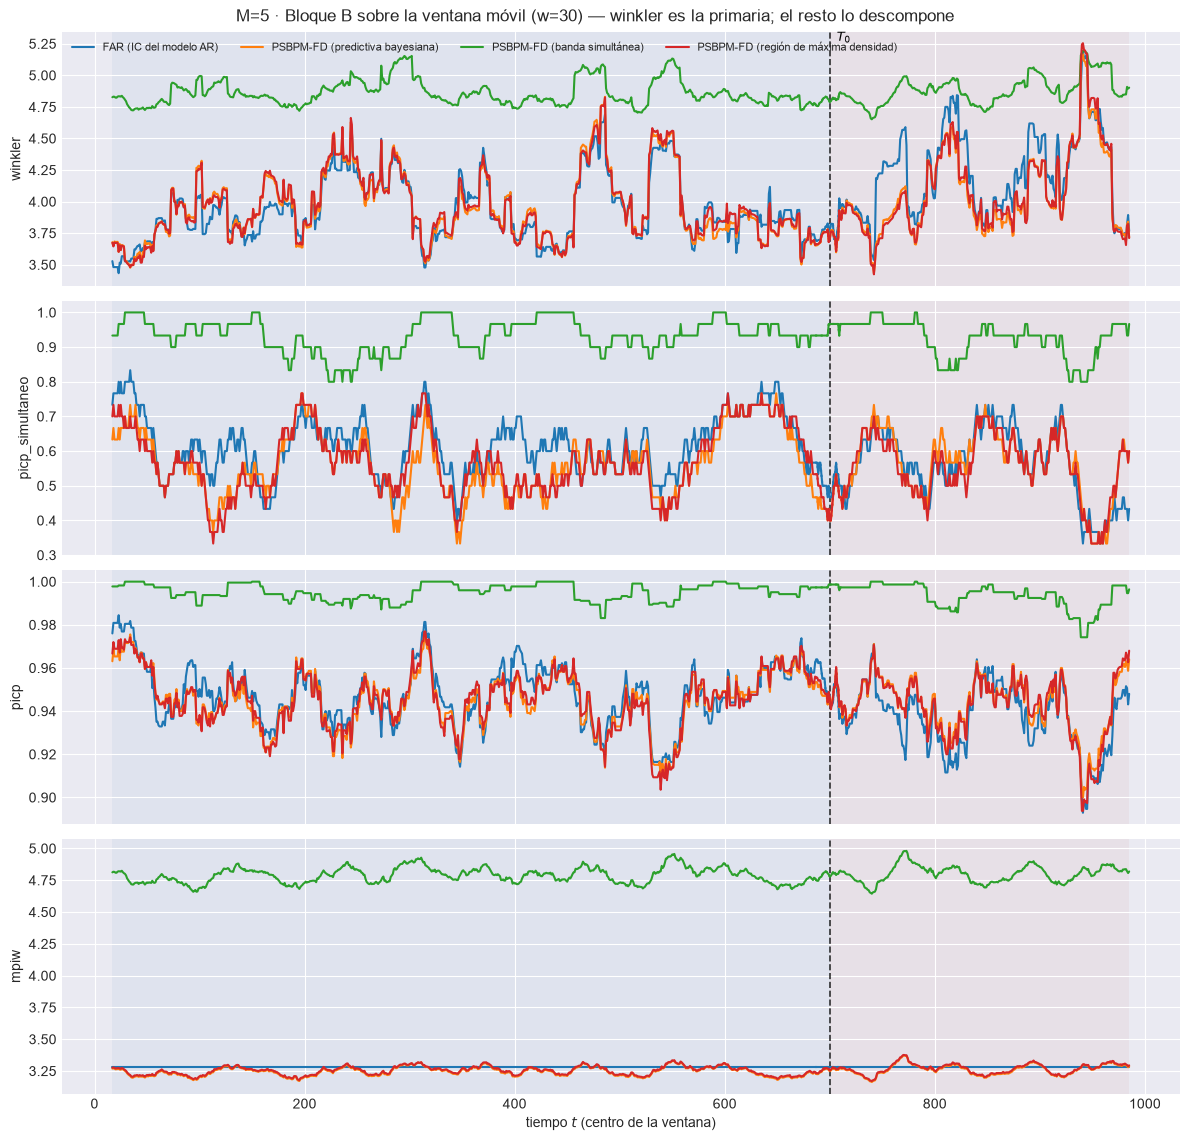

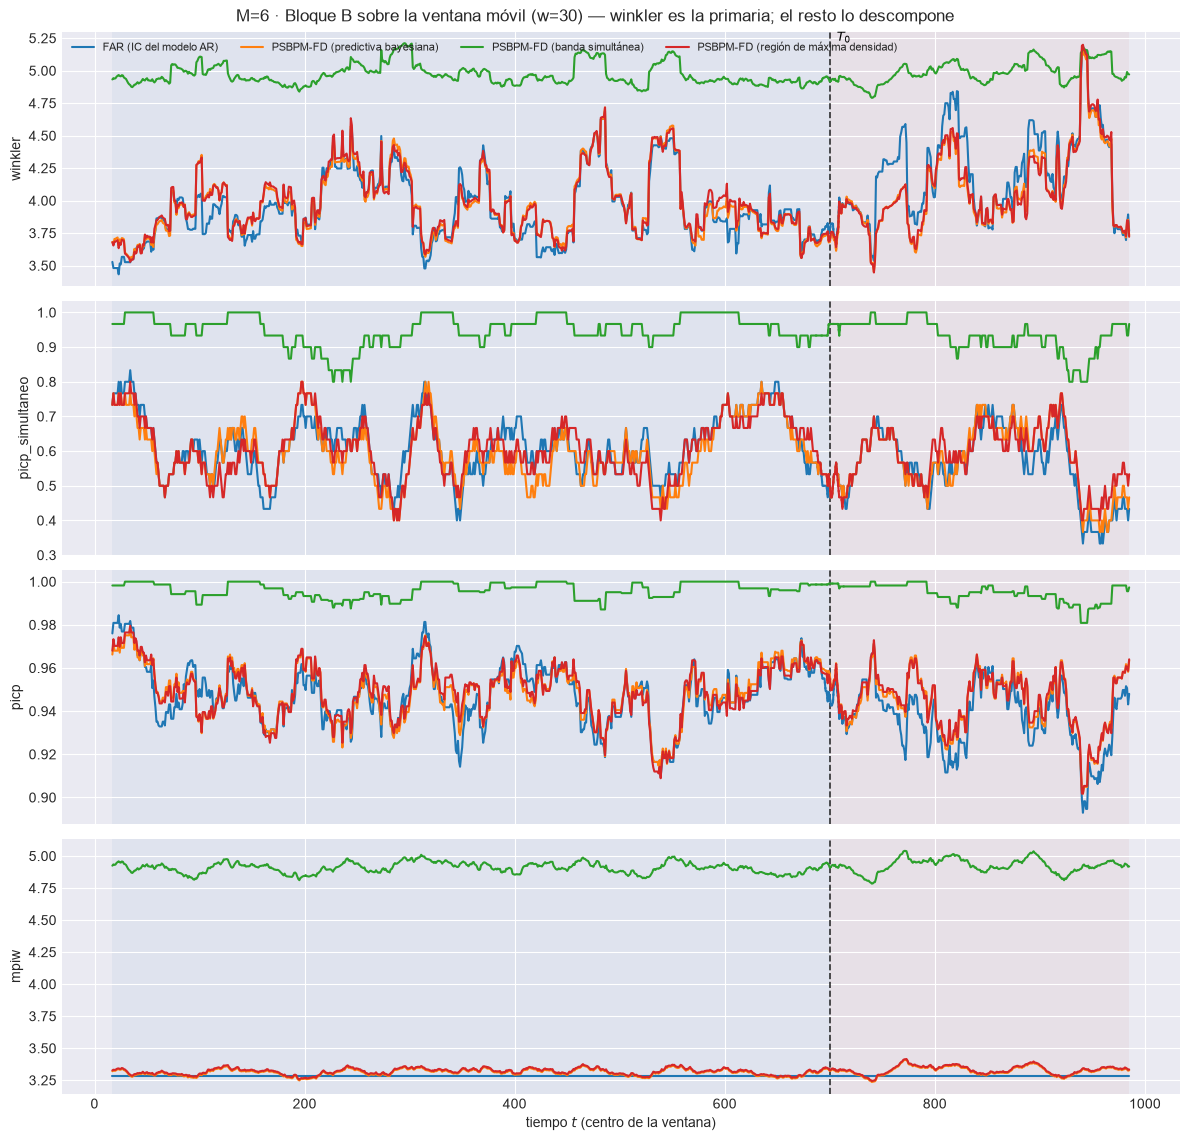

In [11]:
# Winkler sobre la ventana móvil y su descomposición: dice CUÁNDO falla la banda, no sólo cuánto.
for M in M_OK:
    e = EST[M]
    vb = ventana_bloque_B(e, DIS, ORIG, PESOS_TAU, PREFIJO)
    plot_ventana_movil(
        vb, T0, ["winkler", "picp_simultaneo", "picp", "mpiw"], columna_grupo="banda",
        title=f"M={M} · Bloque B sobre la ventana móvil (w={W_REF}) — winkler es la primaria; el resto lo descompone",
        save_path=str(e["paths"]["out_report"] / f"81_ventana_bloqueB_w{W_REF}.png"), verbose=False)
    plt.show()

## 6. Bloque A: quién gana cada ventana, y por cuánto

% de ventanas ganadas y razón contra el mejor y contra el FAR, sin las ventanas que cruzan $T_0$.

M,3,4,5,6
modelo,,,,
FAR,21.8%,14.4%,10.7%,12.5%
PSBPM-FD (esperanza),16.2%,28.4%,33.6%,28.4%
PSBPM-FD (mediana),6.6%,11.4%,11.1%,21.8%
PSBPM-FD (medoide),15.1%,7.7%,14.8%,5.2%
PSBPM-FD (modal),15.5%,22.9%,18.8%,18.8%
RF,24.7%,15.1%,11.1%,13.3%


M,3,4,5,6
modelo,,,,
FAR,1.020,1.021,1.031,1.021
PSBPM-FD (esperanza),1.011,1.006,1.008,1.005
PSBPM-FD (mediana),1.013,1.009,1.010,1.006
PSBPM-FD (medoide),1.015,1.015,1.021,1.021
PSBPM-FD (modal),1.023,1.022,1.021,1.019
RF,1.019,1.020,1.021,1.021


M,3,4,5,6
modelo,,,,
FAR,19.2%,8.5%,7.7%,7.4%
PSBPM-FD (esperanza),24.0%,32.5%,42.8%,33.6%
PSBPM-FD (mediana),2.2%,19.6%,13.7%,24.7%
PSBPM-FD (medoide),10.0%,11.1%,10.0%,7.7%
PSBPM-FD (modal),22.9%,12.2%,12.9%,11.4%
RF,21.8%,16.2%,12.9%,15.1%


M,3,4,5,6
modelo,,,,
FAR,1.021,1.022,1.030,1.023
PSBPM-FD (esperanza),1.009,1.005,1.005,1.005
PSBPM-FD (mediana),1.010,1.007,1.007,1.005
PSBPM-FD (medoide),1.012,1.014,1.020,1.018
PSBPM-FD (modal),1.020,1.023,1.019,1.021
RF,1.017,1.017,1.017,1.018


M,3,4,5,6
modelo,,,,
FAR,18.8%,8.9%,2.6%,4.4%
PSBPM-FD (esperanza),15.1%,41.7%,36.5%,38.0%
PSBPM-FD (mediana),5.9%,10.3%,14.4%,18.5%
PSBPM-FD (medoide),17.3%,13.7%,6.3%,9.6%
PSBPM-FD (modal),34.3%,22.5%,34.7%,24.4%
RF,8.5%,3.0%,5.5%,5.2%


M,3,4,5,6
modelo,,,,
FAR,1.024,1.028,1.037,1.031
PSBPM-FD (esperanza),1.009,1.006,1.007,1.007
PSBPM-FD (mediana),1.011,1.010,1.008,1.008
PSBPM-FD (medoide),1.010,1.014,1.019,1.026
PSBPM-FD (modal),1.013,1.019,1.011,1.015
RF,1.021,1.028,1.026,1.027


M,3,4,5,6
modelo,,,,
FAR,51.3%,41.0%,28.4%,50.2%
PSBPM-FD (esperanza),18.1%,7.7%,12.2%,7.7%
PSBPM-FD (mediana),0.4%,1.5%,1.5%,6.3%
PSBPM-FD (medoide),4.1%,23.2%,19.2%,19.9%
PSBPM-FD (modal),8.5%,3.7%,13.3%,10.3%
RF,17.7%,22.9%,25.5%,5.5%


M,3,4,5,6
modelo,,,,
FAR,1.059,1.061,1.063,1.054
PSBPM-FD (esperanza),1.083,1.073,1.056,1.054
PSBPM-FD (mediana),1.087,1.079,1.056,1.057
PSBPM-FD (medoide),1.085,1.077,1.091,1.049
PSBPM-FD (modal),1.110,1.112,1.094,1.084
RF,1.092,1.090,1.061,1.059


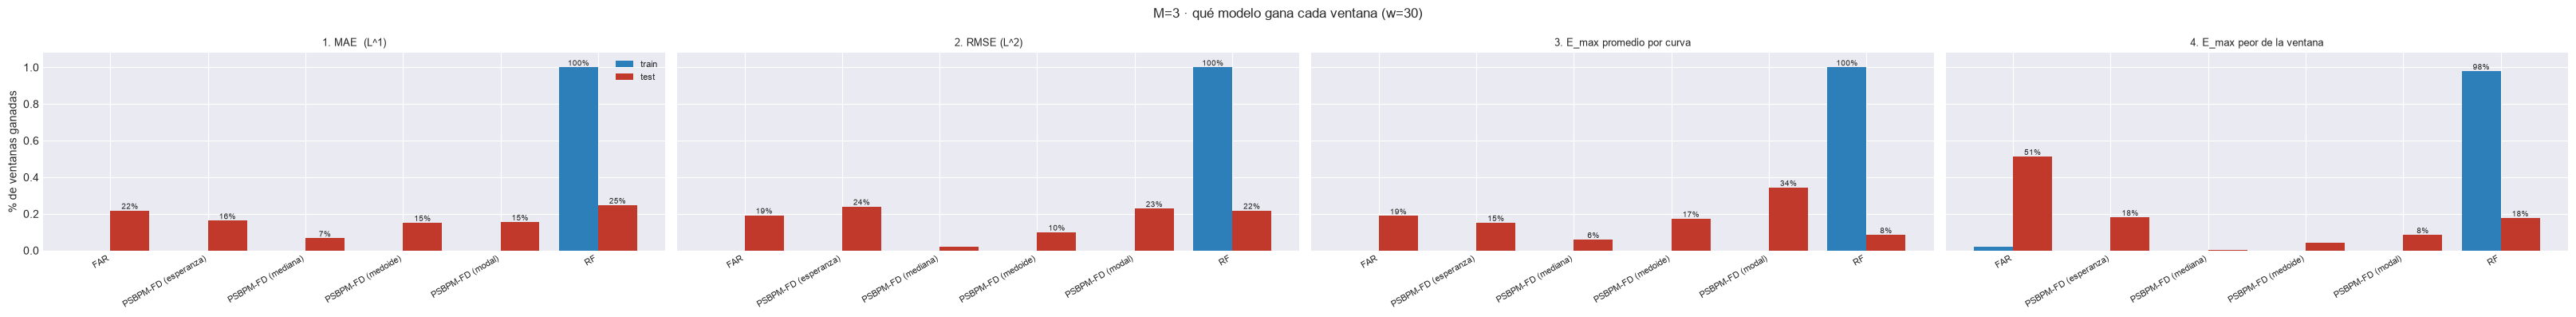

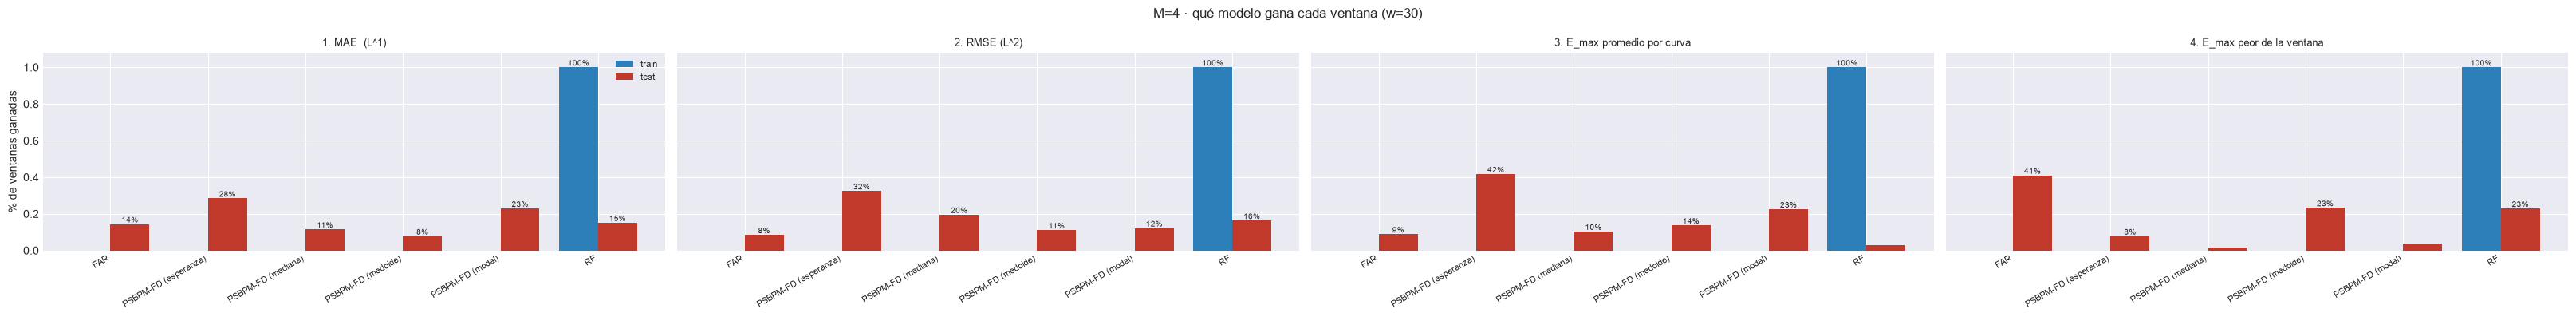

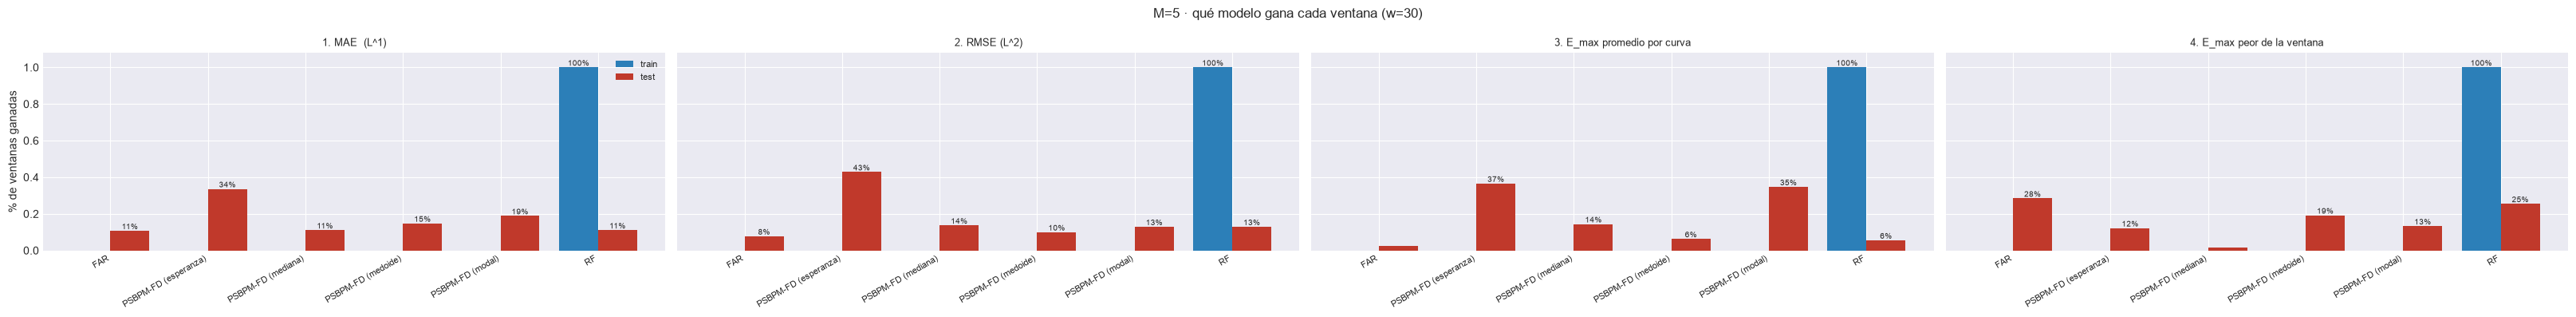

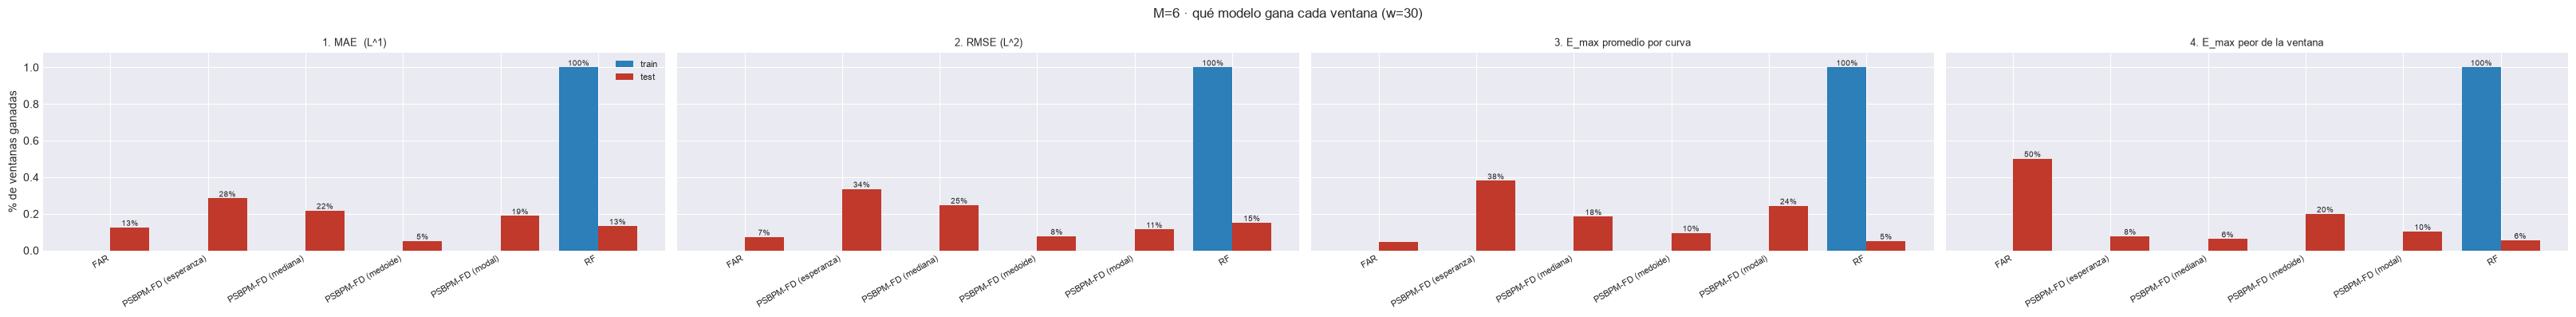

In [12]:
gana_A, rel_A = ganadores_por_ventana(EST, "ventana_df", "modelo", METRICAS_A, NIVEL, excluir=(PISO,))
gana_A.to_csv(PATH_BARRIDO / "96_ganador_ventana_bloqueA.csv", index=False)
rel_A.to_csv(PATH_BARRIDO / "96_razones_bloqueA.csv", index=False)

for etiqueta, _col in METRICAS_A:
    for tabla, v, fmt, cmap, cap in (
            (gana_A, "pct_ventanas_ganadas", "{:.1%}", "RdYlGn",
             f"{etiqueta} · % de ventanas de PRUEBA ganadas (w={W_REF}, sin cruzar T0)"),
            (rel_A, "razon_vs_mejor", "{:.3f}", "RdYlGn_r",
             f"{etiqueta} · razón contra el MEJOR de cada ventana (test) · 1.000 = gana siempre")):
        piv = (tabla[(tabla.metrica == etiqueta) & (tabla.bloque == "test")]
               .pivot(index="modelo", columns="M", values=v))
        display(piv.style.format(fmt, na_rep="-").background_gradient(cmap=cmap, axis=None).set_caption(cap))

for M in M_OK:
    plot_ganador_modelo(gana_A, M, METRICAS_A, W_REF,
                        EST[M]["paths"]["out_report"] / f"{PREFIJO + 8}_ganador_ventana_bloqueA.png")
    plt.show()

In [13]:
# Cada predictor del PSBPM-FD contra FAR y RF por separado (106_ganador_psbp_por_predictor.csv).
partes = []
for p in PREDICTORES:
    otros = [nombre_psbp(q) for q in PREDICTORES if q != p]
    g, _ = ganadores_por_ventana(EST, "ventana_df", "modelo", METRICAS_A, NIVEL, excluir=(PISO, *otros))
    partes.append(g[g.modelo == nombre_psbp(p)].assign(predictor=p))
gana_P = pd.concat(partes, ignore_index=True)
gana_P.to_csv(PATH_BARRIDO / "106_ganador_psbp_por_predictor.csv", index=False)

for etiqueta, _c in METRICAS_A:
    display(gana_P[(gana_P.metrica == etiqueta) & (gana_P.bloque == "test")]
            .pivot(index="predictor", columns="M", values="pct_ventanas_ganadas").loc[list(PREDICTORES)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST que gana el PSBPM-FD con cada predictor, contra FAR y RF"))

M,3,4,5,6
predictor,,,,
esperanza,44.3%,64.2%,63.1%,70.8%
mediana,38.0%,53.9%,59.8%,67.5%
medoide,33.6%,38.7%,42.4%,29.2%
modal,34.3%,28.0%,38.0%,33.2%


M,3,4,5,6
predictor,,,,
esperanza,52.8%,70.5%,68.3%,73.8%
mediana,43.9%,64.9%,64.6%,73.1%
medoide,36.5%,46.9%,43.2%,37.3%
modal,38.0%,24.7%,41.3%,35.4%


M,3,4,5,6
predictor,,,,
esperanza,59.4%,80.8%,86.3%,80.8%
mediana,51.7%,74.5%,88.2%,80.8%
medoide,55.0%,69.4%,56.1%,34.7%
modal,53.1%,46.9%,65.7%,57.9%


M,3,4,5,6
predictor,,,,
esperanza,27.3%,23.6%,25.1%,26.9%
mediana,27.3%,23.6%,18.1%,12.9%
medoide,10.7%,34.3%,32.1%,28.0%
modal,14.0%,17.7%,14.8%,15.9%


## 7. Bloque B: quién gana cada ventana, y por cuánto

Lo mismo sobre las bandas; el Winkler decide.

In [14]:
# En picp / picp_simultaneo "ganar" es estar más cerca del nominal, no tener el valor más bajo.
gana_B, rel_B = ganadores_por_ventana(EST, "ventana_B", "banda", METRICAS_B, NIVEL)
gana_B.to_csv(PATH_BARRIDO / "97_ganador_ventana_bloqueB.csv", index=False)
rel_B.to_csv(PATH_BARRIDO / "97_razones_bloqueB.csv", index=False)

for etiqueta, col in METRICAS_B:
    piv = (gana_B[(gana_B.metrica == etiqueta) & (gana_B.bloque == "test")]
           .pivot(index="banda", columns="M", values="pct_ventanas_ganadas"))
    crit = "más cerca del nominal" if col.startswith("picp") else "menor es mejor"
    display(piv.style.format("{:.1%}", na_rep="-").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas de PRUEBA ganadas (criterio: {crit})"))

M,3,4,5,6
banda,,,,
FAR (IC del modelo AR),0.0%,0.0%,34.7%,89.3%
PSBPM-FD (banda simultánea),0.0%,0.0%,0.0%,0.0%
PSBPM-FD (predictiva bayesiana),100.0%,100.0%,65.3%,10.7%
PSBPM-FD (región de máxima densidad),0.0%,0.0%,0.0%,0.0%


M,3,4,5,6
banda,,,,
FAR (IC del modelo AR),73.1%,62.0%,23.6%,24.4%
PSBPM-FD (banda simultánea),25.8%,11.8%,5.9%,2.6%
PSBPM-FD (predictiva bayesiana),0.0%,16.2%,48.0%,24.4%
PSBPM-FD (región de máxima densidad),1.1%,10.0%,22.5%,48.7%


M,3,4,5,6
banda,,,,
FAR (IC del modelo AR),0.0%,0.0%,0.0%,0.0%
PSBPM-FD (banda simultánea),100.0%,100.0%,100.0%,100.0%
PSBPM-FD (predictiva bayesiana),0.0%,0.0%,0.0%,0.0%
PSBPM-FD (región de máxima densidad),0.0%,0.0%,0.0%,0.0%


M,3,4,5,6
banda,,,,
FAR (IC del modelo AR),55.0%,18.5%,11.1%,18.1%
PSBPM-FD (banda simultánea),17.0%,2.2%,0.0%,0.0%
PSBPM-FD (predictiva bayesiana),6.6%,41.0%,47.2%,46.1%
PSBPM-FD (región de máxima densidad),21.4%,38.4%,41.7%,35.8%


M,3,4,5,6
banda,,,,
FAR (IC del modelo AR),0.0%,0.0%,0.0%,0.0%
PSBPM-FD (banda simultánea),100.0%,100.0%,100.0%,100.0%
PSBPM-FD (predictiva bayesiana),0.0%,0.0%,0.0%,0.0%
PSBPM-FD (región de máxima densidad),0.0%,0.0%,0.0%,0.0%


M,3,4,5,6
banda,,,,
FAR (IC del modelo AR),11.1%,0.0%,0.0%,0.0%
PSBPM-FD (banda simultánea),88.9%,100.0%,100.0%,100.0%
PSBPM-FD (predictiva bayesiana),0.0%,0.0%,0.0%,0.0%
PSBPM-FD (región de máxima densidad),0.0%,0.0%,0.0%,0.0%


## 8. Cuadro resumen: mínimo, máximo y promedio

Por modelo, métrica y bloque, sin las ventanas que cruzan $T_0$.

In [15]:
resumen_A = resumen_min_max(EST, "ventana_df", "modelo", METRICAS_A, excluir=(PISO,))
resumen_B = resumen_min_max(EST, "ventana_B", "banda", METRICAS_B)
resumen_A.to_csv(PATH_BARRIDO / "98_resumen_bloqueA_min_max_prom.csv", index=False)
resumen_B.to_csv(PATH_BARRIDO / "99_resumen_bloqueB_min_max_prom.csv", index=False)

for M in M_OK:
    for res, grupo, fmt, nombre in ((resumen_A, "modelo", "{:.6f}", "Bloque A"), (resumen_B, "banda", "{:.4f}", "Bloque B")):
        sub = (res[(res.M == M) & (res.bloque == "test")]
               .set_index(["metrica", grupo])[["minimo", "maximo", "promedio"]])
        display(sub.style.format(fmt).background_gradient(subset=["maximo"], cmap="RdYlGn_r")
                .set_caption(f"M={M} · {nombre} en el TEST · mínimo / máximo / promedio sobre las ventanas (w={W_REF})"))

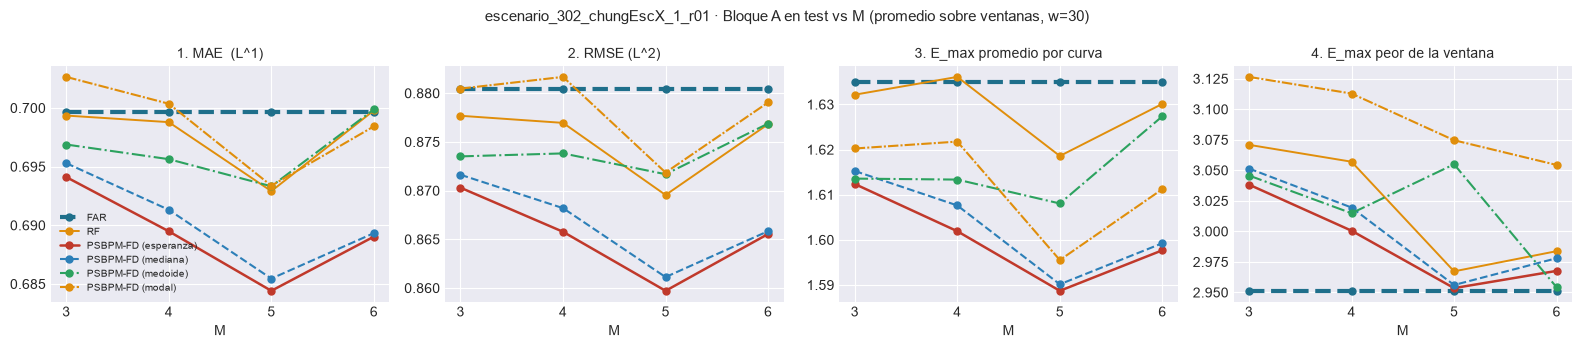

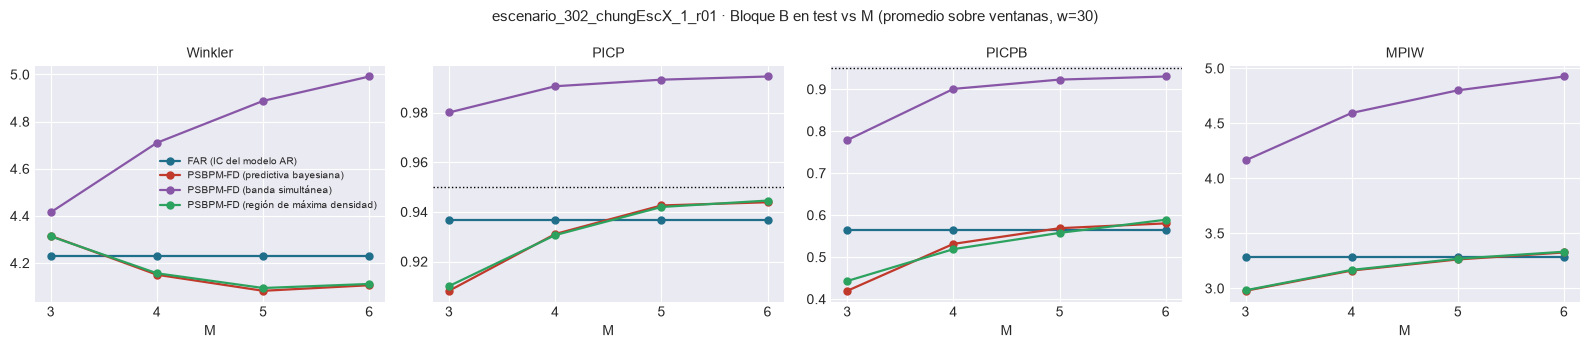

In [16]:
# Las métricas contra M: promedio en test sobre las ventanas, una línea por modelo / banda.
ESTILOS_BANDAS = {G_FAR: dict(color="#1f6f8b"), G_PSG: dict(color="#e08e0b"), G_PSB: dict(color="#c0392b"),
                  G_PSS: dict(color="#8856a7"), G_PSH: dict(color="#2ca25f")}

plot_metricas_vs_M(promedio_vs_M(resumen_A, "modelo"), METRICAS_A, ESTILOS_MODELOS_PREDICTORES,
                   f"{EXPERIMENT_BASE} · Bloque A en test vs M (promedio sobre ventanas, w={W_REF})",
                   save_path=PATH_BARRIDO / f"{PREFIJO + 6}_bloqueA_vs_M.png")
plt.show()
plot_metricas_vs_M(promedio_vs_M(resumen_B, "banda"),
                   [("Winkler", "winkler"), ("PICP", "picp"), ("PICPB", "picp_simultaneo"), ("MPIW", "mpiw")],
                   ESTILOS_BANDAS,
                   f"{EXPERIMENT_BASE} · Bloque B en test vs M (promedio sobre ventanas, w={W_REF})",
                   nominal=NIVEL, save_path=PATH_BARRIDO / f"{PREFIJO + 7}_bloqueB_vs_M.png")
plt.show()

### 8.1 Cada construcción del PSBPM-FD contra el FAR

Winkler medio en test menos el del FAR y % de ventanas ganadas cara a cara (`111_*`).

In [17]:
B_VS_FAR = bloqueB_contra_far(EST, PATH_BARRIDO)
display(B_VS_FAR.style.format(precision=4)
        .set_caption("Bloque B · construcciones del PSBPM-FD contra el FAR (test, w de referencia)"))

,M,banda,n_ventanas,winkler,winkler_FAR,dif_winkler_vs_FAR,pct_ventanas_gana_FAR
0,3,PSBPM-FD (banda simultánea),271,4.4152,4.2305,0.1847,0.2177
1,3,PSBPM-FD (predictiva bayesiana),271,4.3149,4.2305,0.0845,0.2509
2,3,PSBPM-FD (región de máxima densidad),271,4.3130,4.2305,0.0826,0.2731
3,4,PSBPM-FD (banda simultánea),271,4.7102,4.2305,0.4797,0.0332
4,4,PSBPM-FD (predictiva bayesiana),271,4.1501,4.2305,-0.0804,0.7565
5,4,PSBPM-FD (región de máxima densidad),271,4.1562,4.2305,-0.0743,0.7565
6,5,PSBPM-FD (banda simultánea),271,4.8880,4.2305,0.6575,0.0037
7,5,PSBPM-FD (predictiva bayesiana),271,4.0819,4.2305,-0.1485,0.8303
8,5,PSBPM-FD (región de máxima densidad),271,4.0938,4.2305,-0.1367,0.8303
9,6,PSBPM-FD (banda simultánea),271,4.9915,4.2305,0.7610,0.0074


## 9. Intervalos de credibilidad: FAR contra PSBPM-FD, en la ventana de detalle

Tres figuras por $M$ (FAR contra equi-colas, HDR y simultánea) y la tabla de ancho y cobertura por origen, con la cobertura de curva completa como cuenta.

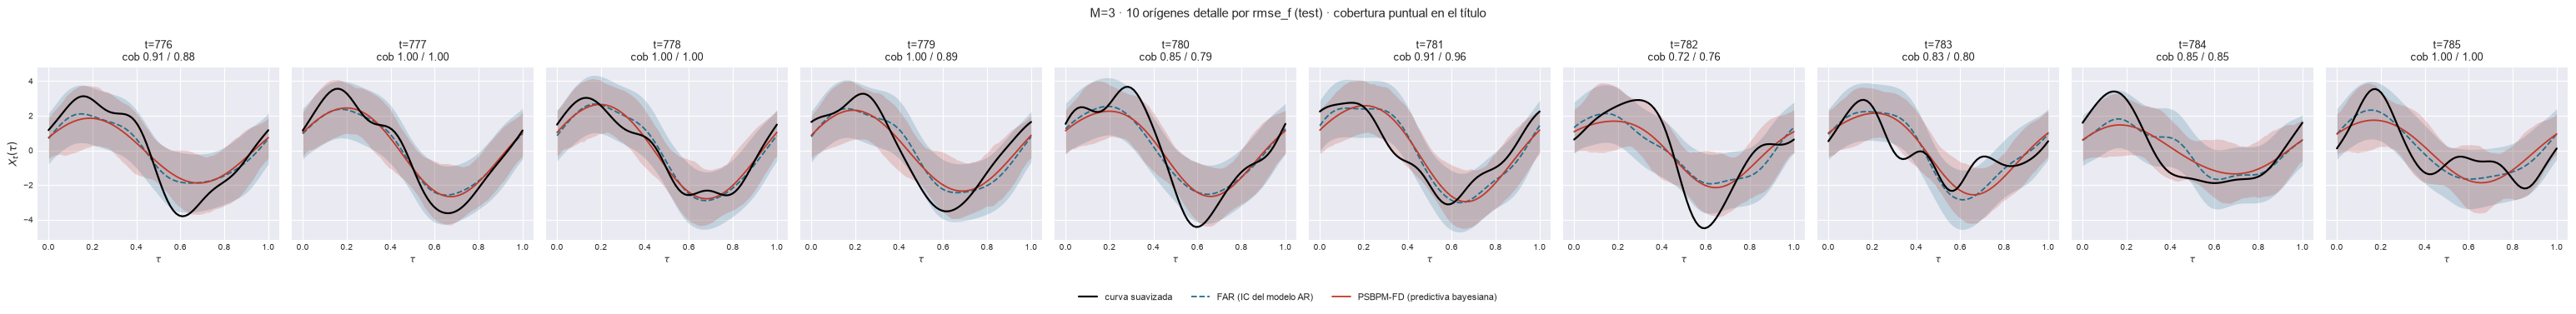

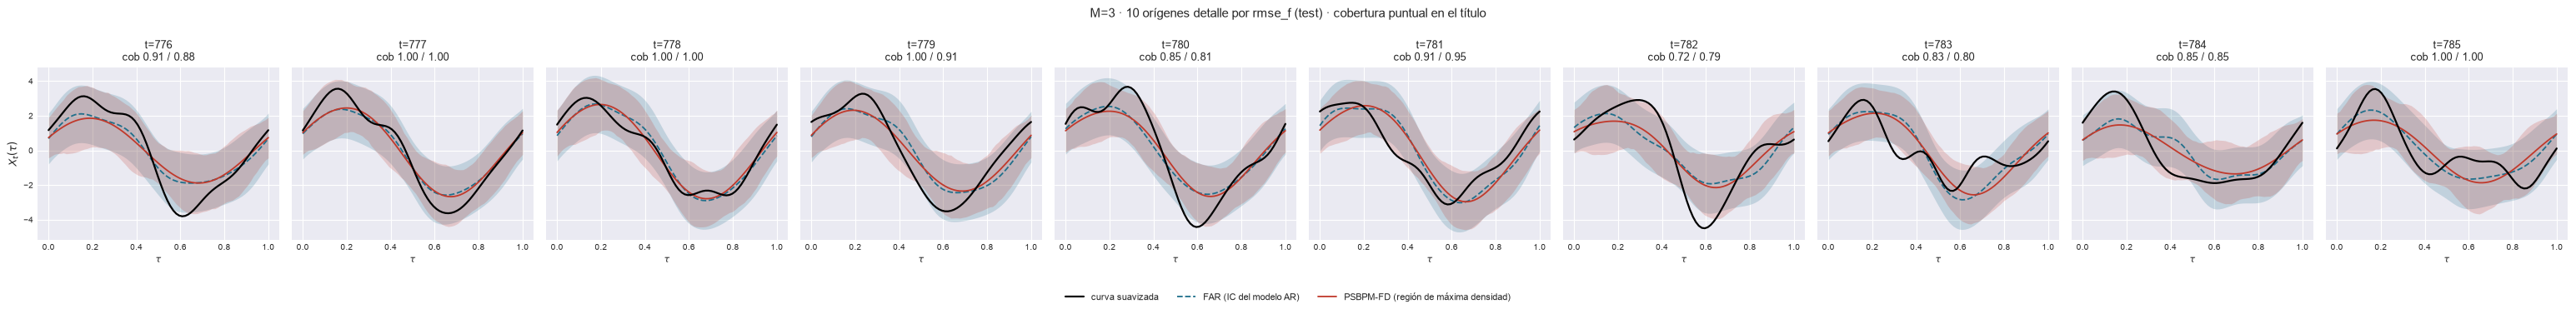

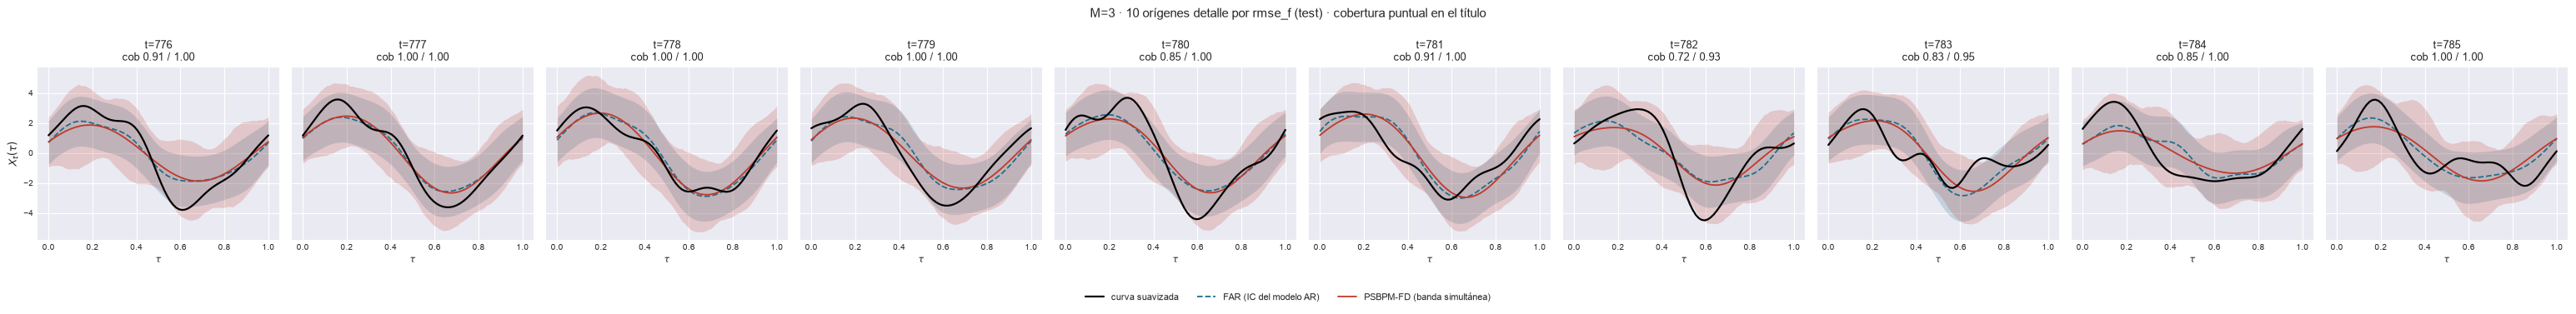

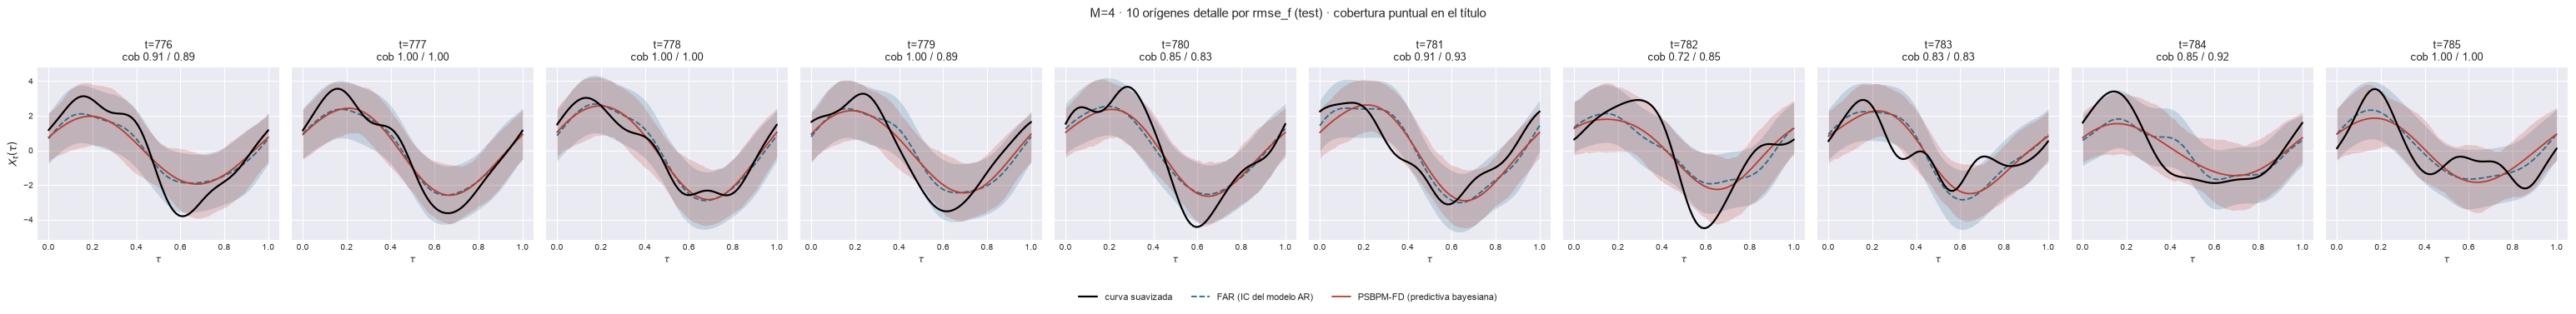

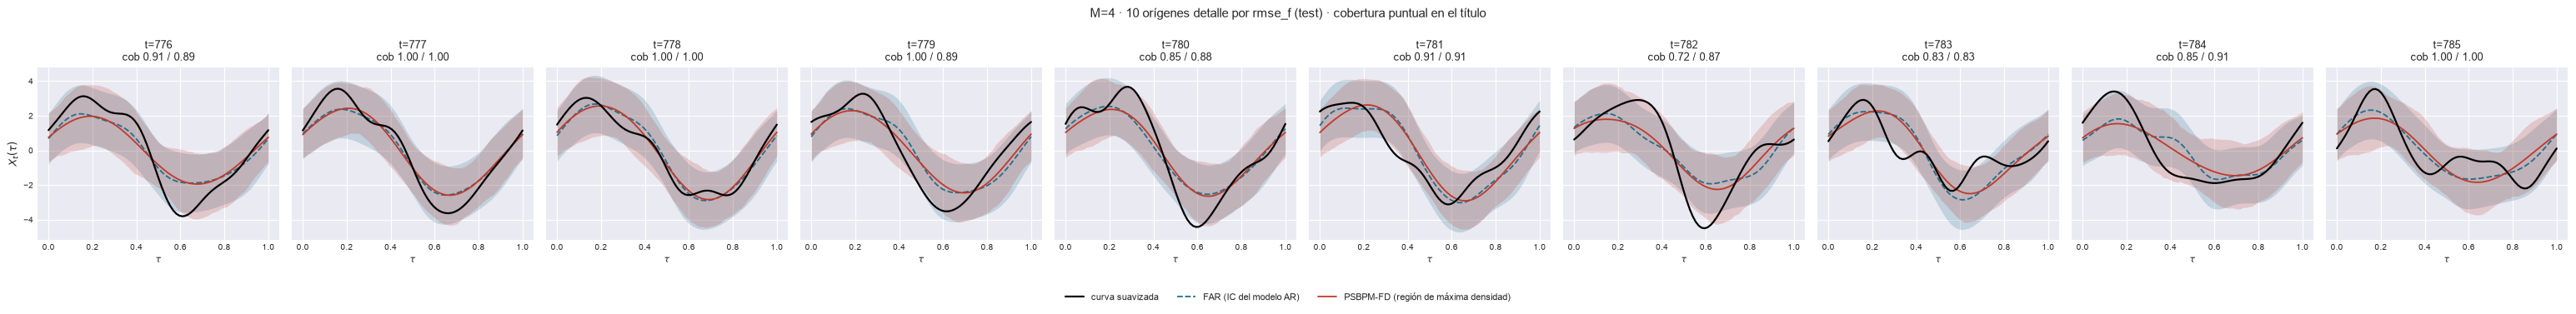

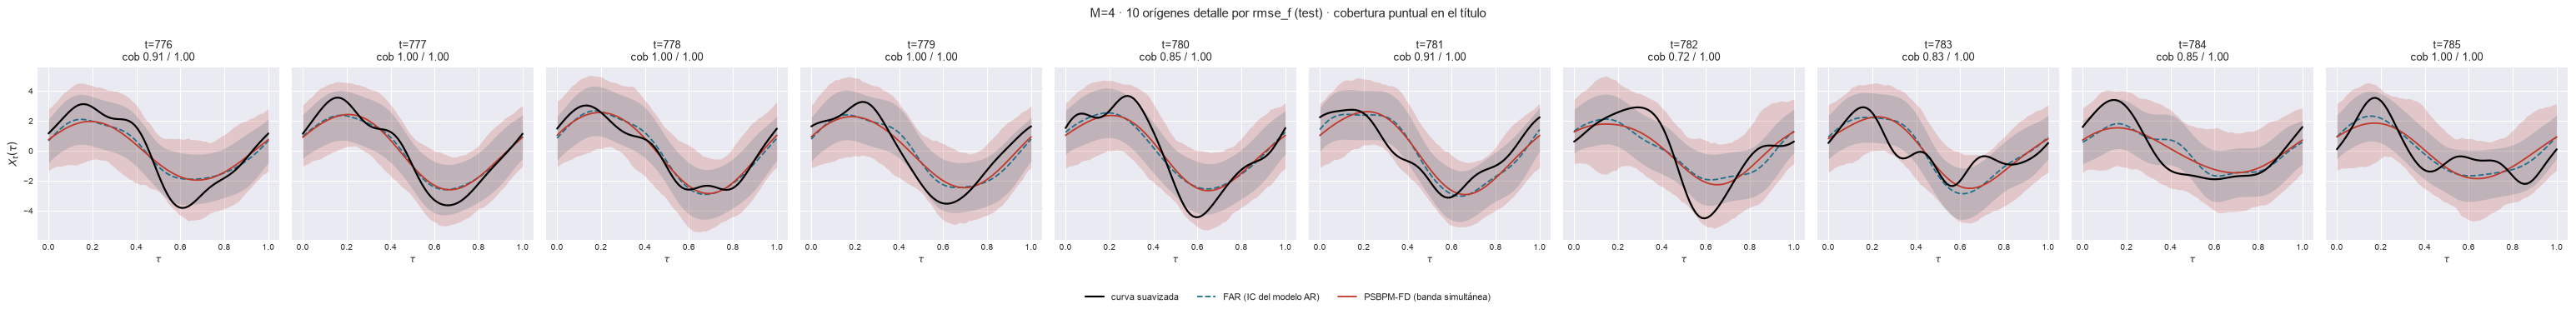

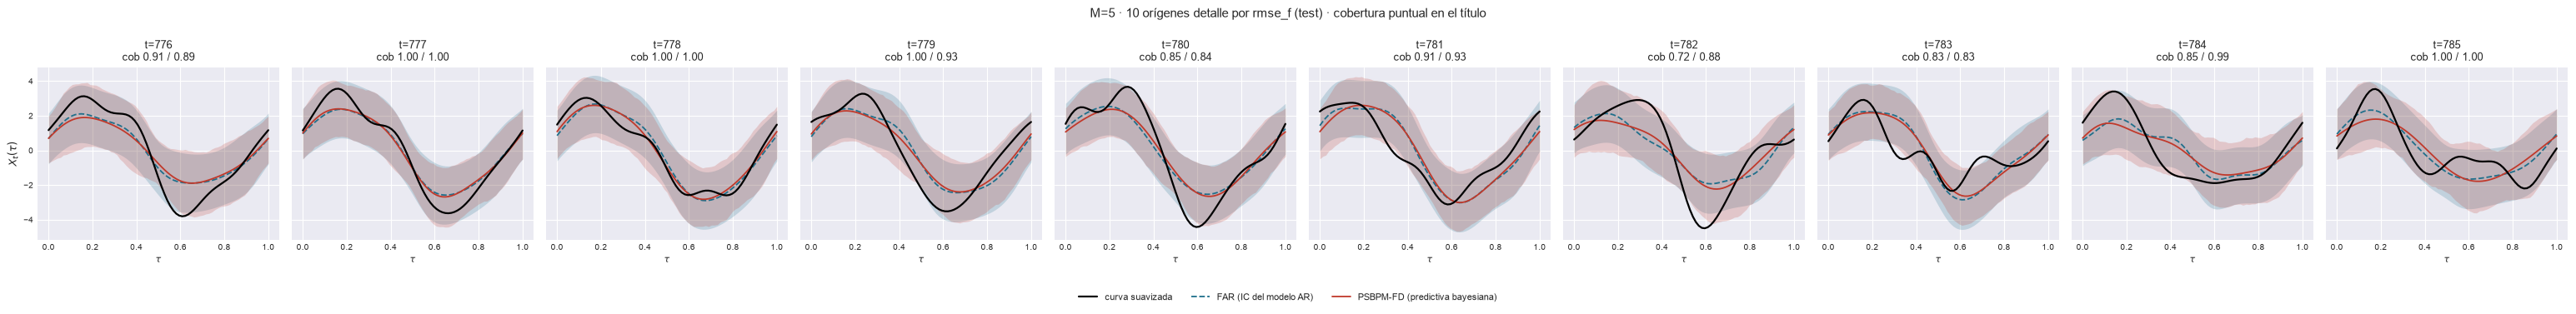

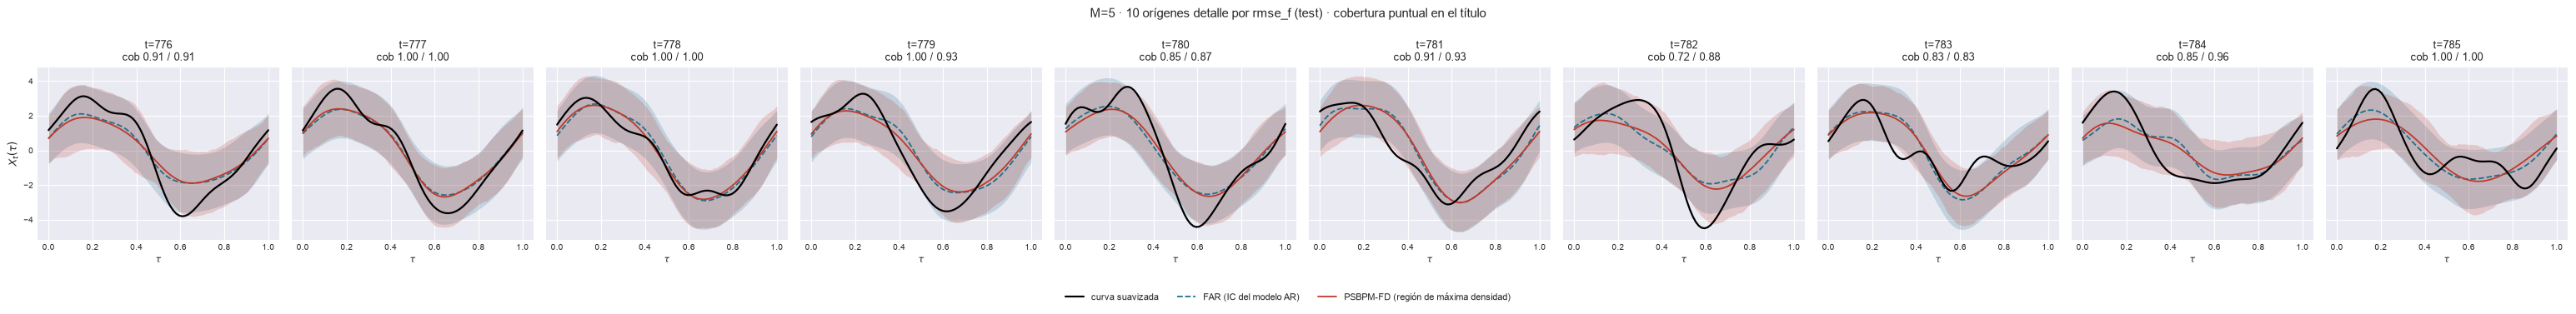

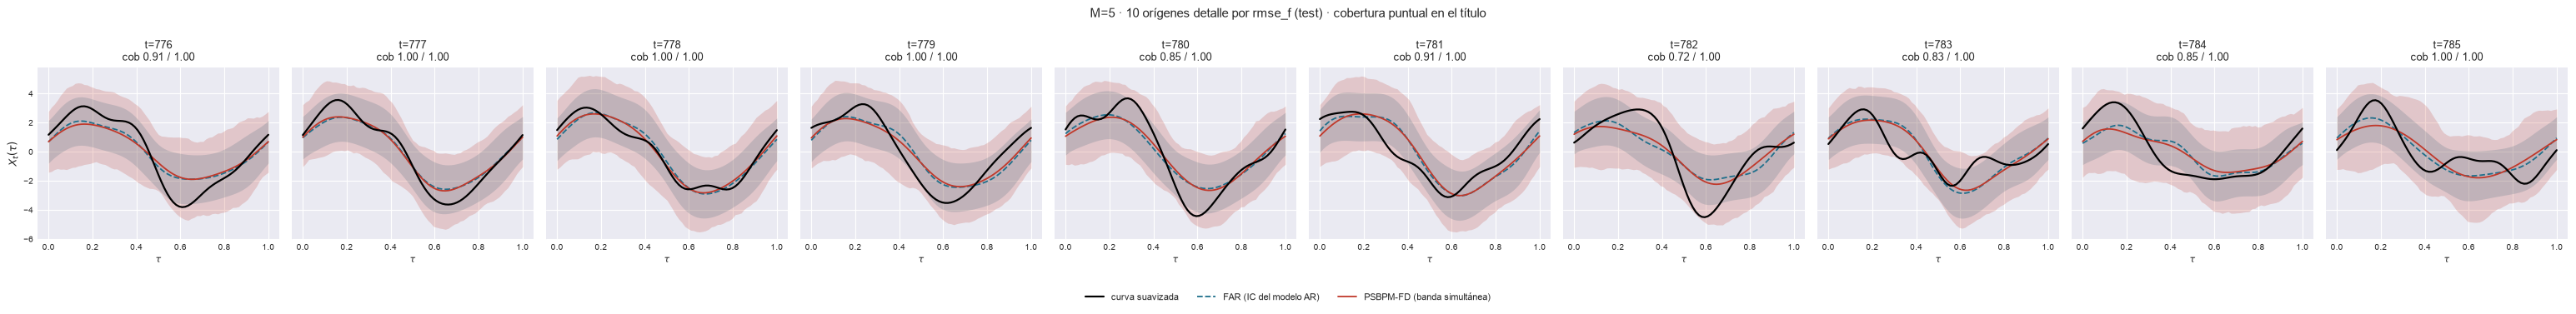

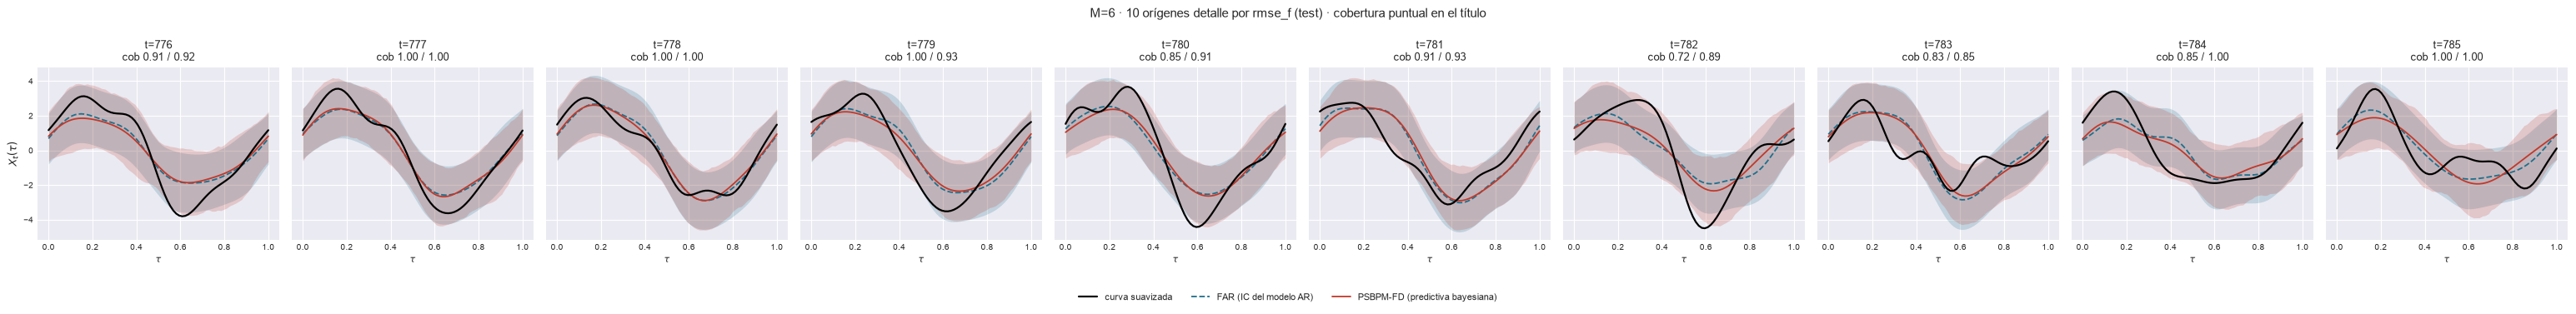

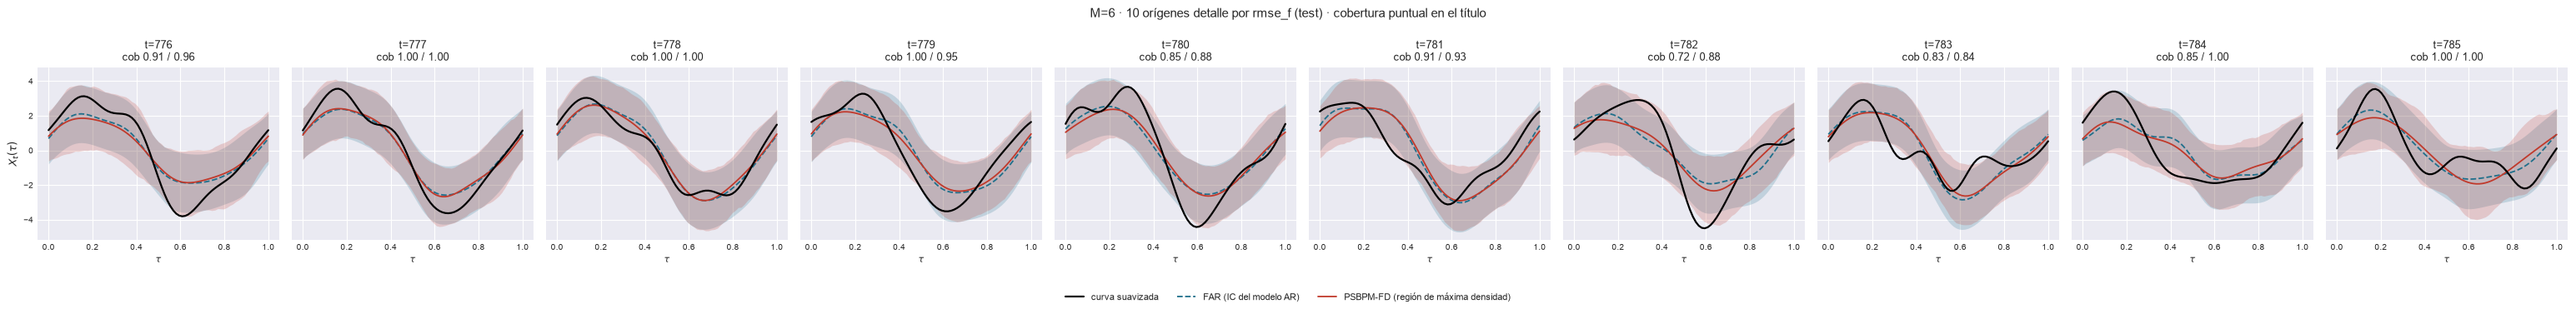

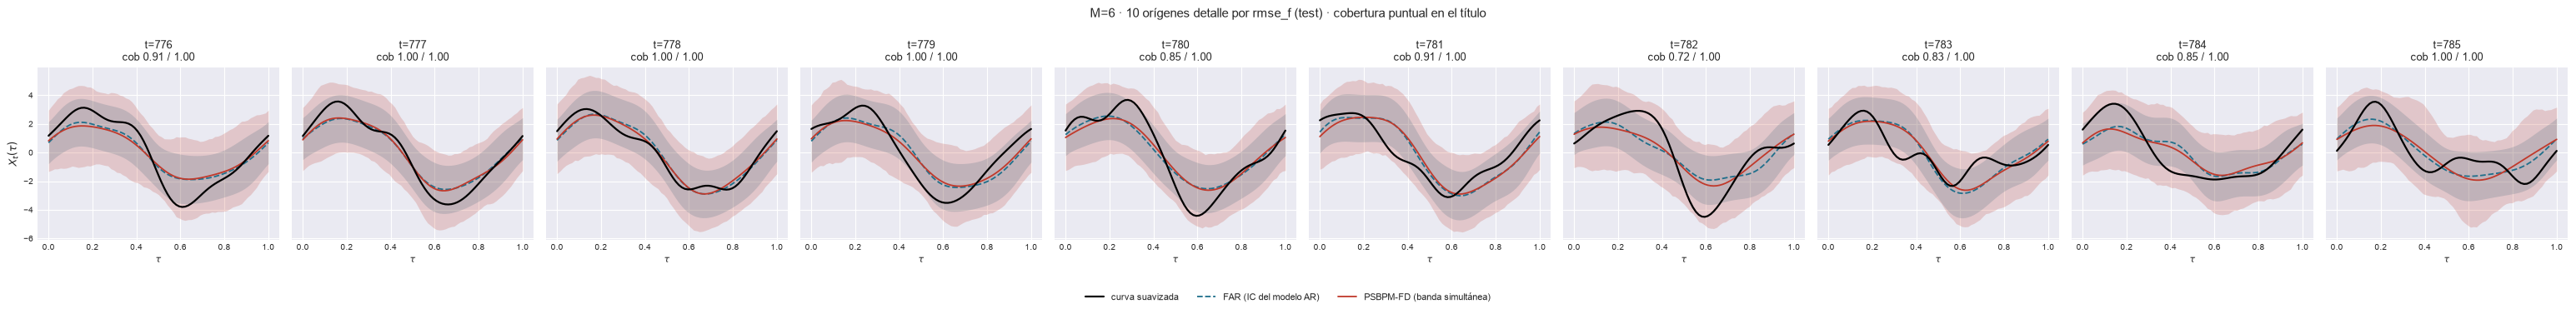

In [18]:
M_9 = M_OK if M_DETALLE is None else tuple(m for m in M_DETALLE if m in M_OK)
DETALLE = {"detalle": IDX_DET}
for M in M_9:
    for par, sufijo in ((BANDA_A_CONTRASTAR, ""), (("FAR", G_PSH), "_hdr"), (("FAR", G_PSS), "_simultanea")):
        plot_bandas_contraste(
            EST[M]["BANDAS"], DETALLE, X_obj_ev, grilla, t_orig, M, METRICA_SEL_IC, par, "detalle",
            EST[M]["paths"]["out_report"] / f"{PREFIJO + 9}_ic_contraste_detalle{sufijo}.png")
        plt.show()

In [19]:
# Ancho y cobertura por origen de cada banda en la ventana de detalle (79_ic_contraste_origenes.csv por M).
filas = []
for M in M_9:
    for i in IDX_DET:
        for nombre, ((L, U), _Xp) in EST[M]["BANDAS"].items():
            dentro = cobertura_tramos(X_obj_ev[i], L[i], U[i])
            filas.append({"M": M, "t": int(t_orig[i]), "banda": nombre,
                          "mpiw": float(ancho_tramos(L[i], U[i]).mean()),
                          "picp_puntual": float(dentro.mean()), "I_t_simultaneo": float(dentro.all())})
ic_df = pd.DataFrame(filas)
for M in M_9:
    ic_df[ic_df.M == M].drop(columns="M").to_csv(
        EST[M]["paths"]["out_report"] / f"{PREFIJO + 9}_ic_contraste_origenes.csv", index=False)
display(ic_df.groupby(["M", "banda"]).agg(mpiw=("mpiw", "mean"), picp_puntual=("picp_puntual", "mean"),
                                          curvas_cubiertas=("I_t_simultaneo", "sum"))
        .style.format({"mpiw": "{:.3f}", "picp_puntual": "{:.3f}", "curvas_cubiertas": "{:.0f}"})
        .set_caption(f"Ventana de detalle (t={T0_DET}..): curvas_cubiertas = cuántas de las {N_DETALLE} "
                     "quedan enteras dentro de la banda (descriptivo)"))
print("Lectura: si el MPIW del FAR es prácticamente el mismo en todos los orígenes, es porque su ancho NO")
print("depende del origen (su Sigma_eps es la misma para todo t); que el del PSBPM-FD cambie entre orígenes")
print("es la flexibilidad de una predictiva que depende del estado.")

Lectura: si el MPIW del FAR es prácticamente el mismo en todos los orígenes, es porque su ancho NO
depende del origen (su Sigma_eps es la misma para todo t); que el del PSBPM-FD cambie entre orígenes
es la flexibilidad de una predictiva que depende del estado.


## 10. Comportamientos predictivos contra lo observado

En la ventana de detalle, como cuentas: comportamiento en que cae lo observado, su probabilidad, si es el más probable, y cobertura, ancho y Winkler de la banda del comportamiento realizado, del más probable y de la marginal, contra $X_t^{(M)}$.

In [20]:
# validar_observado sobre TODO el bloque de prueba (las cifras del cuerpo) y, aparte, sobre la ventana de
# detalle (las cuentas de k de 10). La máscara de los comportamientos se restringe a cada subconjunto. Por
# subconjunto y objetivo, dos filas de resumen: todos los orígenes y sólo K >= 2 (donde el comportamiento
# realizado y el más probable se apartan de la marginal). Error en el origen de la curva típica (realizado =
# cota, más probable = pronóstico) y de las referencias puntuales: esperanza del PSBPM-FD, FAR y RF.
SUBCONJUNTOS = {"test": ~es_train, "detalle": MASK_DET}
partes, res = [], []
for M in M_OK:
    e = EST[M]
    C = cargar_comportamientos(e["paths"])
    assert C is not None and np.array_equal(C["t_orig"], t_orig), f"[M={M}] falta el §12 del _04."
    li_f, ls_f = e["BANDA_PSBP"]
    por_M = []
    for sub, mask in SUBCONJUNTOS.items():
        C["mascara"] = mask.copy()
        for objetivo, Y in (("curva_suavizada", X_obj_ev), ("representacion_fpca", e["X_proj"])):
            v = validar_observado(C, e["Y_obs"], Y, li_f, ls_f, grilla, PESOS_TAU,
                                  curvas_ref={"esperanza": e["X_PSBP"], "FAR": e["CURVAS"]["FAR"],
                                              "RF": e["CURVAS"]["RF"]})
            v.insert(0, "subconjunto", sub)
            v.insert(1, "objetivo", objetivo)
            v.insert(2, "t", t_orig[v["i"].to_numpy()])
            por_M.append(v)
            for grupo, g in (("todos", v), ("K>=2", v[v.K >= 2])):
                fila = {"M": M, "subconjunto": sub, "objetivo": objetivo, "origenes": grupo, "n": int(len(g))}
                if len(g):
                    fila.update({"K >= 2": int((g.K >= 2).sum()),
                                 "cae en el más probable": float(g.acierto.mean()),
                                 "p_obs media": float(g.p_obs.mean()), "p_esperada media": float(g.p_esperada.mean()),
                                 **{f"{m}_{k}": float(g[f"{m}_{k}"].mean()) for m in ("mae", "rmse")
                                    for k in ("real", "mp", "esperanza", "FAR", "RF")},
                                 "mp gana a FAR": float((g.mae_mp < g.mae_FAR).mean()),
                                 "mp gana a RF": float((g.mae_mp < g.mae_RF).mean()),
                                 "mp gana a esperanza": float((g.mae_mp < g.mae_esperanza).mean()),
                                 "curva entera en banda real": float(g.picpb_real.mean()),
                                 "curva entera en banda mp": float(g.picpb_mp.mean()),
                                 "curva entera en banda marginal": float(g.picpb_marg.mean()),
                                 "mpiw_real": float(g.mpiw_real.mean()), "mpiw_mp": float(g.mpiw_mp.mean()),
                                 "mpiw_marg": float(g.mpiw_marg.mean()), "winkler_real": float(g.winkler_real.mean()),
                                 "winkler_mp": float(g.winkler_mp.mean()), "winkler_marg": float(g.winkler_marg.mean())})
                res.append(fila)
    pd.concat(por_M, ignore_index=True).to_csv(e["paths"]["out_report"] / "82_validacion_comportamientos.csv",
                                              index=False)
    pd.DataFrame([r for r in res if r["M"] == M]).to_csv(e["paths"]["out_report"] / "83_validacion_resumen.csv",
                                                         index=False)
VAL_COMP = pd.DataFrame(res).assign(t0_detalle=T0_DET)
VAL_COMP.to_csv(PATH_BARRIDO / "105_validacion_comportamientos_por_M.csv", index=False)
COLS = ["n", "K >= 2", "cae en el más probable", "mae_mp", "mae_real", "mae_esperanza", "mae_FAR", "mae_RF",
        "mp gana a FAR", "mp gana a RF", "mp gana a esperanza", "curva entera en banda marginal"]
for sub, nota in (("test", "fracciones sobre todo el bloque de prueba"),
                  ("detalle", f"ventana de detalle t={T0_DET}..{T0_DET + N_DETALLE - 1}: fracciones de {N_DETALLE} orígenes")):
    display(VAL_COMP[(VAL_COMP.subconjunto == sub) & (VAL_COMP.objetivo == "curva_suavizada")]
            .set_index(["M", "origenes"])[COLS].style.format(precision=3)
            .set_caption(f"Comportamientos contra lo observado · {nota} · objetivo = curva suavizada"))


,origenes,K >= 2,cae en el más probable,p_obs media,p_esperada media,mae_real,mae_mp,mae_esperanza,mae_FAR,mae_RF,rmse_real,rmse_mp,rmse_esperanza,rmse_FAR,rmse_RF,mp gana a FAR,mp gana a RF,mp gana a esperanza,curva entera en banda real,curva entera en banda mp,curva entera en banda marginal,mpiw_real,mpiw_mp,mpiw_marg,winkler_real,winkler_mp,winkler_marg
M,,,,,,,,,,,,,,,,,,,,,,,,,,,
3,10,0,10,1.000,1.000,0.711,0.711,0.714,0.713,0.650,0.824,0.824,0.828,0.856,0.761,6,2,6,8,8,8,3.141,3.141,3.124,3.284,3.284,3.355
4,10,0,10,1.000,1.000,0.731,0.731,0.733,0.737,0.702,0.861,0.861,0.863,0.886,0.830,6,4,5,7,7,6,3.329,3.329,3.294,3.447,3.447,3.564
5,10,0,10,1.000,1.000,0.750,0.750,0.753,0.747,0.691,0.884,0.884,0.887,0.897,0.822,6,3,7,4,4,4,3.421,3.421,3.398,3.833,3.833,3.878
6,10,0,10,1.000,1.000,0.757,0.757,0.759,0.747,0.708,0.899,0.899,0.901,0.908,0.858,5,3,6,6,6,6,3.480,3.480,3.452,3.769,3.769,3.754


,origenes,K >= 2,cae en el más probable,p_obs media,p_esperada media,mae_real,mae_mp,mae_esperanza,mae_FAR,mae_RF,rmse_real,rmse_mp,rmse_esperanza,rmse_FAR,rmse_RF,mp gana a FAR,mp gana a RF,mp gana a esperanza,curva entera en banda real,curva entera en banda mp,curva entera en banda marginal,mpiw_real,mpiw_mp,mpiw_marg,winkler_real,winkler_mp,winkler_marg
M,,,,,,,,,,,,,,,,,,,,,,,,,,,
3,10,0,10,1.000,1.000,0.787,0.787,0.790,0.764,0.728,0.935,0.935,0.937,0.925,0.880,3,2,6,2,2,3,3.141,3.141,3.124,4.362,4.362,4.514
4,10,0,10,1.000,1.000,0.774,0.774,0.776,0.764,0.740,0.924,0.924,0.926,0.925,0.894,6,4,5,4,4,3,3.329,3.329,3.294,4.130,4.130,4.234
5,10,0,10,1.000,1.000,0.765,0.765,0.768,0.764,0.704,0.916,0.916,0.918,0.925,0.854,6,2,8,4,4,3,3.421,3.421,3.398,4.096,4.096,4.146
6,10,0,10,1.000,1.000,0.771,0.771,0.773,0.764,0.726,0.919,0.919,0.921,0.925,0.879,6,3,6,4,4,4,3.480,3.480,3.452,3.961,3.961,3.907
